# How Faithfully Can GANs Learn Five Different Distributions?

## How is the environment set up?

In [1]:
# medmnist (datasets) and the FID stack are the only extras; torch and
# torchvision are preinstalled on Colab.
import subprocess, sys
def _pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)
try:
    import medmnist  # noqa: F401
except Exception:
    _pip("medmnist")
try:
    import torch_fidelity  # noqa: F401  # backend torchmetrics FID needs
except Exception:
    _pip("torchmetrics[image]", "torch-fidelity")

import math, os, json, urllib.parse, urllib.request, pickle
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from scipy import linalg
from scipy.stats import wasserstein_distance
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

SEED = 42
QUICK_MODE = False  # set True for a fast wiring pass (few epochs)

def set_seed(seed=SEED):
    import random
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# One artifact tree for the whole notebook, anchored on the project folder when
# the notebook is run from notebooks/ and on the working directory on Colab, so
# the run leaves its evidence next to the code rather than wherever it started.
# Raw downloads go to a separate data/ tree: they are large and are not evidence,
# so keeping them out of Outputs/ keeps the bundle small enough to copy.
_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = Path(os.environ.get("OUTPUT_DIR", _ROOT / "Outputs"))
DATA_DIR = Path(os.environ.get("DATA_DIR", _ROOT / "data"))
FIG_DIR, METRIC_DIR, CKPT_DIR = OUT / "figures", OUT / "metrics", OUT / "checkpoints"
for _d in (OUT, DATA_DIR, FIG_DIR, METRIC_DIR, CKPT_DIR):
    _d.mkdir(parents=True, exist_ok=True)

print("device:", DEVICE, "| torch:", torch.__version__, "| quick_mode:", QUICK_MODE)
print("artifacts ->", os.path.relpath(OUT, _ROOT), "(figures/, metrics/, checkpoints/)",
      "| raw data ->", os.path.relpath(DATA_DIR, _ROOT))

device: cuda | torch: 2.11.0+cu128 | quick_mode: False
artifacts -> Outputs (figures/, metrics/, checkpoints/) | raw data -> data


## What utilities are shared across tasks?

In [2]:
def make_fixed_noise(num, latent_dim, device, seed=123):
    g = torch.Generator().manual_seed(seed)
    return torch.randn(num, latent_dim, generator=g).to(device)

def real_fake_labels(batch, device, smoothing=0.0):
    real = torch.full((batch, 1), 1.0 - smoothing, device=device)
    fake = torch.zeros((batch, 1), device=device)
    return real, fake

def assert_finite(value, name):
    if not torch.isfinite(value).all():
        raise FloatingPointError(f"Non-finite value in {name}: {value}")

def frechet_distance(feat_real, feat_gen):
    mu_r, mu_g = feat_real.mean(0), feat_gen.mean(0)
    sig_r = np.cov(feat_real, rowvar=False); sig_g = np.cov(feat_gen, rowvar=False)
    diff = mu_r - mu_g
    covmean = linalg.sqrtm(np.atleast_2d(sig_r.dot(sig_g)))
    if isinstance(covmean, tuple):
        covmean = covmean[0]
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    return float(diff.dot(diff) + np.trace(sig_r + sig_g - 2.0 * covmean))

def _sqdist(a, b):
    # |a-b|^2 = |a|^2 + |b|^2 - 2 a.b, avoids materialising an (n, m, d) tensor.
    aa = (a * a).sum(1)[:, None]; bb = (b * b).sum(1)[None, :]
    return np.maximum(aa + bb - 2.0 * a.dot(b.T), 0.0)

def mmd_rbf(x, y, gamma=None, max_n=256):
    # Subsample both sets so the kernels stay max_n x max_n, never n x n. On the
    # 256-d discriminator features this caps the pairwise cost at a few MB.
    x = np.asarray(x, np.float64)[:max_n]; y = np.asarray(y, np.float64)[:max_n]
    if gamma is None:
        pooled = np.vstack([x, y]); sq = _sqdist(pooled, pooled)
        med = np.median(np.sqrt(sq[sq > 0]))
        gamma = 1.0 / (2.0 * med ** 2 + 1e-12)
    kxx = np.exp(-gamma * _sqdist(x, x)); kyy = np.exp(-gamma * _sqdist(y, y))
    kxy = np.exp(-gamma * _sqdist(x, y))
    return float(kxx.mean() + kyy.mean() - 2.0 * kxy.mean())

def denorm(x):
    return (x.clamp(-1, 1) + 1.0) / 2.0

def show_grid(images, title="", nrow=8, save=None):
    imgs = denorm(images.detach().cpu()); n = imgs.shape[0]
    nrows = int(np.ceil(n / nrow))
    fig, axes = plt.subplots(nrows, nrow, figsize=(nrow, nrows))
    axes = np.array(axes).reshape(-1)
    for i, ax in enumerate(axes):
        ax.axis("off")
        if i < n:
            ax.imshow(imgs[i, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    if title: fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    if save: fig.savefig(save, dpi=120)
    plt.show()

def montage(images, nrow=4):
    # Tile the first nrow*nrow single-channel images into one array. Used for the
    # epoch-progress panels: a single sample per epoch cannot show diversity or
    # mode collapse, a tile of 16 from the same fixed noise can.
    imgs = denorm(images.detach().cpu())[:nrow * nrow, 0].numpy()
    n, h, w = imgs.shape
    if n < nrow * nrow:
        imgs = np.concatenate([imgs, np.zeros((nrow * nrow - n, h, w), imgs.dtype)])
    return imgs.reshape(nrow, nrow, h, w).transpose(0, 2, 1, 3).reshape(nrow * h, nrow * w)

def loss_trend(hist, tol=0.15):
    # Direction of travel of both losses plus a named training regime, written to
    # disk so the discussion can cite produced output instead of asserting an
    # outcome in prose. Every training loop here SUMS the two discriminator BCE
    # terms (real and fake) and uses a single term for the generator, so the
    # chance equilibrium, where the discriminator outputs 0.5 on everything, is
    # 2*ln2 for loss_d and ln2 for loss_g. One-sided label smoothing does not
    # move those targets: BCE evaluated at p = 0.5 equals ln2 for any soft label.
    # The bands are fixed here, before any run, rather than chosen after seeing a
    # number.
    d0, g0 = float(hist[0, 0]), float(hist[0, 1])
    d1, g1 = float(hist[-1, 0]), float(hist[-1, 1])
    eq_d, eq_g = 2.0 * math.log(2.0), math.log(2.0)
    def direction(a, b):
        return "rising" if b > a else ("falling" if b < a else "flat")
    if not (math.isfinite(d1) and math.isfinite(g1)):
        regime = "diverging (non-finite final loss)"
    elif d1 < (1.0 - tol) * eq_d and g1 > (1.0 + tol) * eq_g:
        regime = "discriminator-dominant"
    elif d1 > (1.0 + tol) * eq_d and g1 < (1.0 - tol) * eq_g:
        regime = "generator-dominant"
    elif abs(d1 - eq_d) <= tol * eq_d and abs(g1 - eq_g) <= tol * eq_g:
        regime = "near-equilibrium"
    else:
        regime = "mixed (neither side at the chance equilibrium, neither clearly ahead)"
    return {"epochs": int(hist.shape[0]),
            "loss_d_first": d0, "loss_d_last": d1, "loss_d_direction": direction(d0, d1),
            "loss_g_first": g0, "loss_g_last": g1, "loss_g_direction": direction(g0, g1),
            "loss_convention": "loss_d = BCE(D(real), real) + BCE(D(fake), fake) summed; "
                               "loss_g = BCE(D(fake), real label)",
            "chance_equilibrium_loss_d": eq_d, "chance_equilibrium_loss_g": eq_g,
            "regime_tolerance": tol, "regime": regime,
            "discriminator_dominant": bool(regime == "discriminator-dominant")}

def diversity_and_memorisation(gen, real_ref, train_ref, cap=1000, ref_cap=2000, seed=SEED):
    """Measure how spread out the generated images are, and how close they sit to
    the training data.

    Two failure modes need telling apart and neither is visible in a Frechet
    distance. Collapse shows as a shrunken spread, so the mean pairwise Euclidean
    distance among generated samples is reported against the same statistic on
    real samples. Memorisation shows as generated samples lying closer to the
    training split than genuine unseen real images do, so the mean
    nearest-neighbour distance from generated samples to the training split is
    reported against the real-to-training baseline. Both run on flattened pixels
    with the sample counts capped, so the pairwise matrices stay small. The bands
    are heuristic and are fixed here before the run.
    """
    rng = np.random.default_rng(seed)
    def flat(x, k):
        # Subsample first, widen to float64 second: the training reference can be
        # tens of thousands of images and casting all of them would allocate
        # hundreds of megabytes for no benefit.
        a = x.detach().cpu().numpy().reshape(x.shape[0], -1)
        if a.shape[0] > k:
            a = a[rng.choice(a.shape[0], k, replace=False)]
        return a.astype(np.float64)
    g, r, t = flat(gen, cap), flat(real_ref, cap), flat(train_ref, ref_cap)
    def mean_pairwise(a):
        d = np.sqrt(_sqdist(a, a)); iu = np.triu_indices(len(a), 1)
        return float(d[iu].mean())
    def mean_nn(a, b):
        return float(np.sqrt(_sqdist(a, b)).min(axis=1).mean())
    def safe_ratio(num, den):
        # A zero numerator is a genuine result (a collapsed generator really does
        # have zero spread); only a zero or non-finite denominator means the
        # comparison could not be formed. Keeping NaN out of the returned dict
        # matters because the self-check rejects non-finite metrics.
        if den > 0 and math.isfinite(num) and math.isfinite(num / den):
            return float(num / den), True
        return 0.0, False

    sp_g, sp_r = mean_pairwise(g), mean_pairwise(r)
    ratio, ratio_ok = safe_ratio(sp_g, sp_r)
    if not ratio_ok:
        spread_verdict = "not computable (real reference spread is zero)"
    elif ratio < 0.50:
        spread_verdict = "generated spread far below real (consistent with mode collapse)"
    elif ratio < 0.85:
        spread_verdict = "generated spread below real (reduced diversity)"
    elif ratio <= 1.15:
        spread_verdict = "generated spread comparable to real"
    else:
        spread_verdict = "generated spread above real (over-dispersed)"
    nn_g, nn_r = mean_nn(g, t), mean_nn(r, t)
    nn_ratio, nn_ok = safe_ratio(nn_g, nn_r)
    if not nn_ok:
        memorisation_verdict = "not computable (real reference distance is zero)"
    elif nn_ratio < 0.80:
        memorisation_verdict = ("generated samples sit closer to the training split than held-out "
                                "real images do (memorisation not ruled out)")
    else:
        memorisation_verdict = ("generated samples are no closer to the training split than held-out "
                                "real images are")
    return {"samples_compared": int(len(g)), "train_reference_samples": int(len(t)),
            "space": "flattened 32x32 pixels in [-1, 1]",
            "generated_mean_pairwise_distance": sp_g,
            "real_mean_pairwise_distance": sp_r,
            "diversity_ratio": float(ratio), "diversity_ratio_computable": bool(ratio_ok),
            "spread_verdict": spread_verdict,
            "generated_mean_nn_distance_to_train": nn_g,
            "real_mean_nn_distance_to_train": nn_r,
            "nn_distance_ratio": float(nn_ratio), "nn_distance_ratio_computable": bool(nn_ok),
            "memorisation_verdict": memorisation_verdict}

def grayscale_to_tensor(images, image_size=32):
    x = torch.from_numpy(images.astype(np.float32) / 255.0)
    if x.dim() == 3: x = x.unsqueeze(1)
    elif x.dim() == 4 and x.shape[-1] == 1: x = x.permute(0, 3, 1, 2)
    x = F.interpolate(x, size=(image_size, image_size), mode="bilinear", align_corners=False)
    return x * 2.0 - 1.0

def compute_inception_fid(real, fake, min_n=2048, chunk=256):
    # True Inception FID (torchmetrics, Inception v3). real/fake are (N,1,32,32)
    # in [-1,1]; denormalised to [0,1], expanded to 3 channels and cast to uint8;
    # Inception resizes to 299 internally. Requires at least min_n samples per
    # side; at n = d = 2048 the covariance is only just at the edge of full rank,
    # so FID here is biased upward rather than unbiased. Chunked updates bound
    # memory. Fails loudly if the backend is missing rather than
    # returning a silent stand-in. Not comparable across members unless the full
    # protocol is identical.
    from torchmetrics.image.fid import FrechetInceptionDistance
    n = min(real.shape[0], fake.shape[0])
    if n < min_n:
        raise ValueError(f"Inception FID needs >= {min_n} samples per side, got {n}. "
                         "Provide a larger held-out real split / generate more samples.")
    def prep(x):
        x = denorm(x).repeat(1, 3, 1, 1)
        return (x * 255).clamp(0, 255).to(torch.uint8)
    metric = FrechetInceptionDistance(feature=2048, normalize=False).to(DEVICE)
    for i in range(0, n, chunk):
        metric.update(prep(real[i:i + chunk]).to(DEVICE), real=True)
    for i in range(0, n, chunk):
        metric.update(prep(fake[i:i + chunk]).to(DEVICE), real=False)
    return {"inception_fid": float(metric.compute().item()),
            "fid_extractor": "InceptionV3 (torchmetrics, ImageNet weights)",
            "fid_inputs": "grayscale->3ch, [0,255] uint8, resized to 299 internally",
            "fid_sample_count": int(n),
            "method": "inception_v3_fid_torchmetrics_feature2048_heldout"}

## How is the Part 1 synthetic 2D GAN built?

In [3]:
def make_sine(n=1024, seed=SEED):
    g = torch.Generator().manual_seed(seed)
    x = 2 * math.pi * torch.rand(n, 1, generator=g); y = torch.sin(x)
    return torch.cat([x, y], 1)

def make_gaussian_mixture(n=1024, modes=8, radius=2.0, std=0.10, seed=SEED):
    rng = np.random.default_rng(seed)
    ang = np.linspace(0, 2 * math.pi, modes, endpoint=False)
    centres = np.stack([radius * np.cos(ang), radius * np.sin(ang)], 1)
    idx = rng.integers(0, modes, n)
    pts = centres[idx] + rng.normal(scale=std, size=(n, 2))
    return torch.tensor(pts, dtype=torch.float32)

DISTS = {"sine": make_sine, "gaussian_mixture": make_gaussian_mixture}

class P1Discriminator(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 256), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, 1), nn.Sigmoid())
    def forward(self, x): return self.net(x)

class P1Generator(nn.Module):
    def __init__(self, variant="baseline", latent_dim=2):
        super().__init__(); self.latent_dim = latent_dim
        if variant == "baseline":
            self.net = nn.Sequential(nn.Linear(latent_dim, 16), nn.ReLU(),
                                     nn.Linear(16, 32), nn.ReLU(), nn.Linear(32, 2))
        else:
            self.net = nn.Sequential(
                nn.Linear(latent_dim, 64), nn.LeakyReLU(0.2),
                nn.Linear(64, 64), nn.LeakyReLU(0.2),
                nn.Linear(64, 32), nn.LeakyReLU(0.2), nn.Linear(32, 2))
    def forward(self, z): return self.net(z)

def train_part1(distribution, variant, epochs=2000, lr=1e-3, batch=32, latent_dim=2):
    set_seed()
    if QUICK_MODE: epochs = 200
    data = DISTS[distribution]()
    loader = DataLoader(TensorDataset(data), batch_size=batch, shuffle=True)
    G = P1Generator(variant, latent_dim).to(DEVICE); D = P1Discriminator().to(DEVICE)
    crit = nn.BCELoss()
    optG = torch.optim.Adam(G.parameters(), lr=lr); optD = torch.optim.Adam(D.parameters(), lr=lr)
    hist = []
    for ep in range(epochs):
        ed = eg = nb = 0
        for (real,) in loader:
            real = real.to(DEVICE); cur = real.shape[0]
            rl, fl = real_fake_labels(cur, DEVICE)
            optD.zero_grad()
            loss_dr = crit(D(real), rl)
            z = torch.randn(cur, latent_dim, device=DEVICE); fake = G(z)
            loss_df = crit(D(fake.detach()), fl)
            loss_d = loss_dr + loss_df; assert_finite(loss_d, "loss_d")
            loss_d.backward(); optD.step()
            for p in D.parameters(): p.requires_grad_(False)
            optG.zero_grad()
            loss_g = crit(D(fake), rl); assert_finite(loss_g, "loss_g")
            loss_g.backward(); optG.step()
            for p in D.parameters(): p.requires_grad_(True)
            ed += loss_d.item(); eg += loss_g.item(); nb += 1
        hist.append((ed / nb, eg / nb))
        if ep % max(1, epochs // 10) == 0 or ep == epochs - 1:
            print(f"[{distribution}/{variant}] epoch {ep}/{epochs} loss_d={ed/nb:.3f} loss_g={eg/nb:.3f}")
    # Checkpoint, full loss history and the run configuration are written to disk
    # so the figures and numbers can be regenerated without retraining (P1-06).
    hist = np.array(hist)
    name = f"part1_{distribution}_{variant}"
    ckpt = CKPT_DIR / f"{name}.pt"
    config = {"distribution": distribution, "variant": variant, "latent_dim": latent_dim,
              "epochs": epochs, "lr": lr, "batch_size": batch, "seed": SEED,
              "optimiser": "Adam", "loss": "BCE"}
    torch.save({"generator_state": G.state_dict(), "config": config,
                "final_loss_d": float(hist[-1][0]), "final_loss_g": float(hist[-1][1])}, ckpt)
    np.savetxt(METRIC_DIR / f"{name}_losses.csv", hist,
               delimiter=",", header="loss_d,loss_g", comments="")
    json.dump({**config, **loss_trend(hist)}, open(METRIC_DIR / f"{name}_run.json", "w"), indent=2)
    G.eval()
    with torch.no_grad():
        gen = G(make_fixed_noise(1000, latent_dim, DEVICE)).cpu().numpy()
    return {"G": G, "hist": hist, "real": data.numpy(), "gen": gen,
            "distribution": distribution, "variant": variant, "ckpt": ckpt}

In [4]:
# P1-01 sine baseline, P1-02 new distribution, P1-03 architecture modification
p1_sine = train_part1("sine", "baseline")
p1_mix_base = train_part1("gaussian_mixture", "baseline")
p1_mix_mod  = train_part1("gaussian_mixture", "modified")

[sine/baseline] epoch 0/2000 loss_d=0.700 loss_g=1.059
[sine/baseline] epoch 200/2000 loss_d=1.280 loss_g=0.834
[sine/baseline] epoch 400/2000 loss_d=1.343 loss_g=0.784
[sine/baseline] epoch 600/2000 loss_d=1.353 loss_g=0.744
[sine/baseline] epoch 800/2000 loss_d=1.315 loss_g=0.807
[sine/baseline] epoch 1000/2000 loss_d=1.365 loss_g=0.734
[sine/baseline] epoch 1200/2000 loss_d=1.329 loss_g=0.812
[sine/baseline] epoch 1400/2000 loss_d=1.256 loss_g=1.010
[sine/baseline] epoch 1600/2000 loss_d=1.313 loss_g=0.789
[sine/baseline] epoch 1800/2000 loss_d=1.366 loss_g=0.722
[sine/baseline] epoch 1999/2000 loss_d=1.367 loss_g=0.717
[gaussian_mixture/baseline] epoch 0/2000 loss_d=0.822 loss_g=0.838
[gaussian_mixture/baseline] epoch 200/2000 loss_d=0.968 loss_g=1.701
[gaussian_mixture/baseline] epoch 400/2000 loss_d=0.982 loss_g=1.348
[gaussian_mixture/baseline] epoch 600/2000 loss_d=0.979 loss_g=1.281
[gaussian_mixture/baseline] epoch 800/2000 loss_d=1.052 loss_g=1.167
[gaussian_mixture/baseline

## How is Part 1 evaluated?

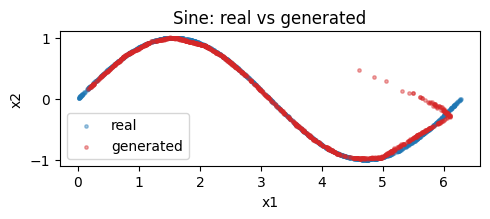

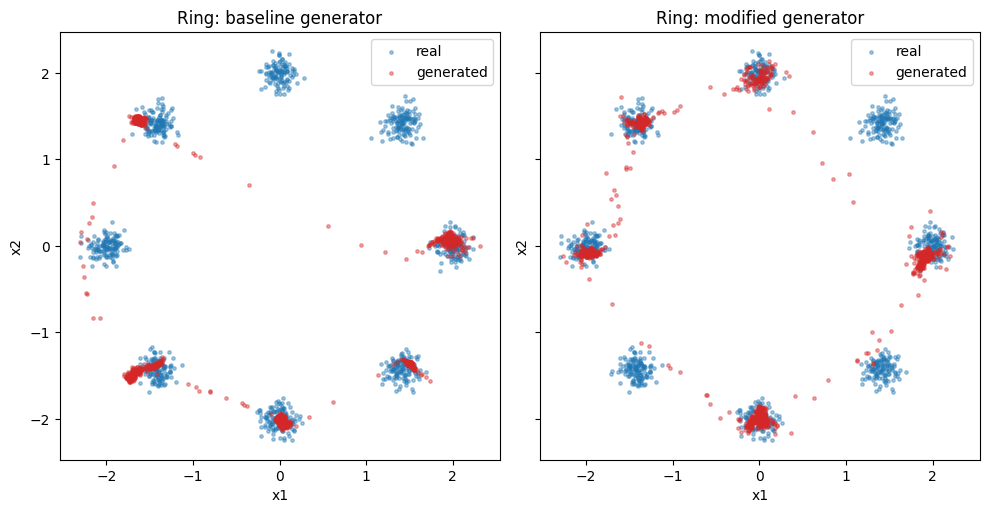

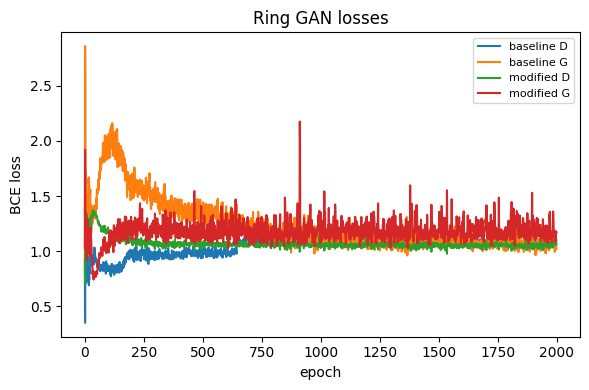

{
  "note": "wasserstein/mmd measure within-mode fit; mode_coverage measures how many of the 8 modes are hit. Read them together.",
  "baseline": {
    "wasserstein": 0.43044094675278144,
    "mmd": 0.050077242995236304,
    "mode_coverage": {
      "modes_covered": 5,
      "modes_total": 8,
      "coverage_threshold_samples": 10,
      "per_mode_counts": [
        252,
        0,
        0,
        143,
        1,
        144,
        249,
        118
      ],
      "uncovered_modes": [
        1,
        2,
        4
      ],
      "off_manifold_fraction": 0.093
    }
  },
  "modified": {
    "wasserstein": 0.3096568607463436,
    "mmd": 0.0035910851398295307,
    "mode_coverage": {
      "modes_covered": 5,
      "modes_total": 8,
      "coverage_threshold_samples": 10,
      "per_mode_counts": [
        225,
        0,
        99,
        142,
        157,
        2,
        294,
        6
      ],
      "uncovered_modes": [
        1,
        5,
        7
      ],
      "off_mani

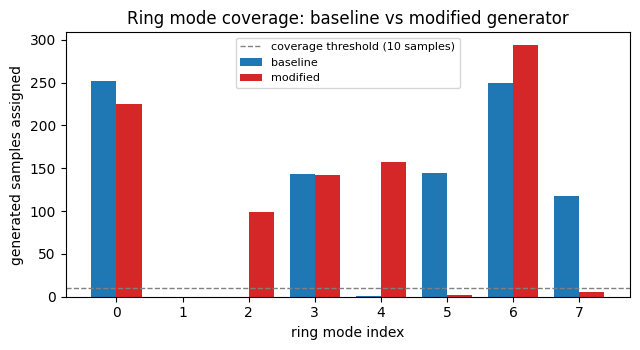

In [5]:
def coord_wasserstein(real, gen):
    return float(np.mean([wasserstein_distance(real[:, d], gen[:, d]) for d in range(real.shape[1])]))

def ring_mode_coverage(gen, modes=8, radius=2.0, std=0.10, tol=3.0):
    # How many of the known ring modes receive samples. A point counts toward a
    # mode if within tol*std of that centre; a mode is covered if it holds at
    # least 1% of samples. Aggregate Wasserstein/MMD are blind to dropped modes,
    # so this is reported alongside them for the P1-05 comparison.
    ang = np.linspace(0, 2 * math.pi, modes, endpoint=False)
    centres = np.stack([radius * np.cos(ang), radius * np.sin(ang)], 1)
    d = np.linalg.norm(gen[:, None, :] - centres[None, :, :], axis=-1)
    nearest = d.argmin(1); mind = d.min(1)
    counts = np.bincount(nearest[mind < tol * std], minlength=modes)
    thr = max(1, int(0.01 * len(gen)))
    return {"modes_covered": int((counts >= thr).sum()), "modes_total": modes,
            "coverage_threshold_samples": int(thr),
            "per_mode_counts": counts.tolist(),
            "uncovered_modes": [int(i) for i in np.where(counts < thr)[0]],
            "off_manifold_fraction": float((mind >= tol * std).mean())}

def scatter_real_gen(res, ax, title):
    ax.scatter(res["real"][:, 0], res["real"][:, 1], s=6, alpha=0.4, label="real", color="#1f77b4")
    ax.scatter(res["gen"][:, 0], res["gen"][:, 1], s=6, alpha=0.4, label="generated", color="#d62728")
    ax.set_title(title); ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(loc="best")

# sine baseline
fig, ax = plt.subplots(figsize=(5, 5)); scatter_real_gen(p1_sine, ax, "Sine: real vs generated")
ax.set_aspect("equal", adjustable="box"); fig.tight_layout()
fig.savefig(FIG_DIR / "p1_sine.png", dpi=150); plt.show()

# baseline vs modified on the Gaussian ring
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
scatter_real_gen(p1_mix_base, axes[0], "Ring: baseline generator")
scatter_real_gen(p1_mix_mod,  axes[1], "Ring: modified generator")
for ax in axes: ax.set_aspect("equal", adjustable="box")
fig.tight_layout(); fig.savefig(FIG_DIR / "p1_compare.png", dpi=150); plt.show()

# loss curves
fig, ax = plt.subplots(figsize=(6, 4))
for res, lab in [(p1_mix_base, "baseline"), (p1_mix_mod, "modified")]:
    ax.plot(res["hist"][:, 0], label=f"{lab} D"); ax.plot(res["hist"][:, 1], label=f"{lab} G")
ax.set_xlabel("epoch"); ax.set_ylabel("BCE loss"); ax.set_title("Ring GAN losses"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "p1_losses.png", dpi=150); plt.show()

comparison = {
  "note": "wasserstein/mmd measure within-mode fit; mode_coverage measures how "
          "many of the 8 modes are hit. Read them together.",
  "baseline": {"wasserstein": coord_wasserstein(p1_mix_base["real"], p1_mix_base["gen"]),
               "mmd": mmd_rbf(p1_mix_base["real"], p1_mix_base["gen"]),
               "mode_coverage": ring_mode_coverage(p1_mix_base["gen"])},
  "modified": {"wasserstein": coord_wasserstein(p1_mix_mod["real"], p1_mix_mod["gen"]),
               "mmd": mmd_rbf(p1_mix_mod["real"], p1_mix_mod["gen"]),
               "mode_coverage": ring_mode_coverage(p1_mix_mod["gen"])},
}

# P1-05 verdict, decided from this run's own numbers rather than asserted in the
# discussion. Fit and coverage are separate questions and can disagree, so the
# verdict names both and flags the case where the two distances point different
# ways, which is exactly the case where neither arm can be called better.
_w_better = comparison["modified"]["wasserstein"] < comparison["baseline"]["wasserstein"]
_m_better = comparison["modified"]["mmd"] < comparison["baseline"]["mmd"]
_cov_delta = (comparison["modified"]["mode_coverage"]["modes_covered"]
              - comparison["baseline"]["mode_coverage"]["modes_covered"])
if _w_better and _m_better:
    _fit_verdict = "modified fits tighter on both distances"
elif _w_better or _m_better:
    _fit_verdict = "the two distances disagree on which arm fits tighter"
else:
    _fit_verdict = "baseline fits tighter on both distances"
if _cov_delta > 0:
    _cov_verdict = f"modified covers {_cov_delta} more ring mode(s)"
elif _cov_delta < 0:
    _cov_verdict = f"modified covers {-_cov_delta} fewer ring mode(s)"
else:
    _cov_verdict = "both arms cover the same number of ring modes"
comparison["verdict"] = {"wasserstein_favours_modified": bool(_w_better),
                         "mmd_favours_modified": bool(_m_better),
                         "distances_agree": bool(_w_better == _m_better),
                         "coverage_delta_modified_minus_baseline": int(_cov_delta),
                         "fit": _fit_verdict, "coverage": _cov_verdict}
json.dump(comparison, open(METRIC_DIR / "p1_comparison.json", "w"), indent=2)
print(json.dumps(comparison, indent=2))

# P1-05 read-out. The two families of number can disagree, so print the direction
# of travel for each one instead of leaving the reader to infer it from the JSON.
base_cov, mod_cov = comparison["baseline"]["mode_coverage"], comparison["modified"]["mode_coverage"]
print("\nP1-05 baseline vs modified (equal draws of 1000 samples):")
for arm in ("baseline", "modified"):
    a = comparison[arm]
    print(f"  {arm:8s} wasserstein={a['wasserstein']:.4f} mmd={a['mmd']:.5f} "
          f"modes_covered={a['mode_coverage']['modes_covered']}/{a['mode_coverage']['modes_total']} "
          f"uncovered={a['mode_coverage']['uncovered_modes']} "
          f"counts={a['mode_coverage']['per_mode_counts']}")
print(f"  within-mode fit improved: wasserstein={comparison['modified']['wasserstein'] < comparison['baseline']['wasserstein']}, "
      f"mmd={comparison['modified']['mmd'] < comparison['baseline']['mmd']}")
print(f"  mode coverage changed: {mod_cov['modes_covered'] != base_cov['modes_covered']} "
      f"(baseline {base_cov['modes_covered']} -> modified {mod_cov['modes_covered']})")
print(f"  modes below the {base_cov['coverage_threshold_samples']}-sample threshold in both arms: "
      f"{sorted(set(base_cov['uncovered_modes']) & set(mod_cov['uncovered_modes']))}")
print(f"  P1-05 VERDICT: {comparison['verdict']['fit']}; {comparison['verdict']['coverage']}.")

# Per-mode counts as a figure so the coverage claim has a visual as well as a
# printed source.
idx = np.arange(base_cov["modes_total"]); w = 0.38
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.bar(idx - w / 2, base_cov["per_mode_counts"], w, label="baseline", color="#1f77b4")
ax.bar(idx + w / 2, mod_cov["per_mode_counts"], w, label="modified", color="#d62728")
ax.axhline(base_cov["coverage_threshold_samples"], color="grey", ls="--", lw=1,
           label=f"coverage threshold ({base_cov['coverage_threshold_samples']} samples)")
ax.set_xlabel("ring mode index"); ax.set_ylabel("generated samples assigned")
ax.set_xticks(idx); ax.set_title("Ring mode coverage: baseline vs modified generator")
ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(FIG_DIR / "p1_mode_coverage.png", dpi=150); plt.show()

## Which architecture reproduces the ring better?

Sine baseline. The scatter plot is the whole test for the tutorial target. The
generated points should trace the same single-valued curve over x in [0, 2*pi] as
the real ones: y bounded in [-1, 1], one branch, no cloud of points off the curve
and no stretch of the domain that is never generated. This target has a single
connected mode, which is the easiest case for a small GAN, so a good fit here says
the training loop is correct, not that the model is strong. The loss curves are a
diagnostic of the game, not of sample quality: a discriminator loss collapsing
towards zero would mean the generator has stopped receiving useful gradients.

Seed sensitivity. Everything here is one seed, fixed in the setup cell and
re-applied at the start of every training call. Small 2D GANs are sensitive to
initialisation, and the ring in particular can settle on a different subset of
modes from run to run. Re-running with a different seed is the direct way to see
how much of the result is the architecture and how much is the draw; that sweep is
not run here, and no claim in this notebook depends on the result being
seed-stable.

Baseline versus modified. The two families of measure printed above answer
different questions and can point in opposite directions, so both are needed
before the modification is called an improvement.

Wasserstein and MMD are aggregate distances. They reward samples that sit tightly
on the modes the generator has already found, and they are close to blind to a
mode that receives no samples at all: dropping one of eight equally weighted blobs
moves an averaged 1D distance only slightly. The mode-coverage count is the
opposite. It ignores how tight each cluster is and asks only how many of the eight
known ring centres receive at least the printed threshold of samples.

The read-out line reports whether each distance fell, whether the covered-mode
count changed, and which mode indices stay below the threshold in both arms, and
it ends with a printed P1-05 verdict naming the outcome. That verdict, not this
paragraph, is where the direction of the result comes from, and there are four
readings to keep apart.

If both distances fall while the coverage count and the shared uncovered set are
unchanged, the deeper LeakyReLU generator has tightened its fit to the part of the
ring it already reached rather than found more of the target. That is a narrower
claim than calling the modification better, and it is the most likely outcome for
a change that adds capacity without changing the training signal. If the covered
count rises, the extra depth has bought coverage, which is the more valuable
result on a multimodal target because it means whole regions of the data
distribution that were previously empty are now being generated. If both
distances rise, the extra capacity has cost fit, which on a small 2D problem
usually means the larger generator is harder for a fixed discriminator and a fixed
2000-epoch budget to balance. And if the two distances disagree with each other,
neither can carry the claim on its own: an averaged 1D Wasserstein distance and a
kernel MMD weight the tails differently, and a split between them is a signal that
the difference between the arms is within run-to-run noise rather than a property
of the architecture.

The per-mode bar chart shows the same information without averaging. Any bar
below the dashed threshold line is a ring centre the corresponding arm has
effectively failed to reach, and comparing the two bars at each index separates a
generator that redistributed its samples across modes from one that only
concentrated harder on the modes it already had.

The comparison is fair in the sense that both arms share the seed, the data, the
discriminator, the optimiser, the learning rate, the epoch count and the number of
evaluation samples; only the generator differs. It is still a single seed, so the
coverage counts are one observation rather than a property of either architecture.
Repeating both arms over several seeds and reporting the spread is the obvious
next step and is not done here.

## What DCGAN do the image tasks share?

In [6]:
class DCGANGenerator(nn.Module):
    def __init__(self, latent_dim=100, feat=64, ch=1):
        super().__init__(); self.latent_dim = latent_dim
        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, feat*4, 4, 1, 0, bias=False), nn.BatchNorm2d(feat*4), nn.ReLU(True),
            nn.ConvTranspose2d(feat*4, feat*2, 4, 2, 1, bias=False), nn.BatchNorm2d(feat*2), nn.ReLU(True),
            nn.ConvTranspose2d(feat*2, feat, 4, 2, 1, bias=False), nn.BatchNorm2d(feat), nn.ReLU(True),
            nn.ConvTranspose2d(feat, ch, 4, 2, 1, bias=False), nn.Tanh())
    def forward(self, z):
        if z.dim() == 2: z = z.view(z.size(0), z.size(1), 1, 1)
        return self.net(z)

class DCGANDiscriminator(nn.Module):
    def __init__(self, feat=64, ch=1):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(ch, feat, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, True),
            nn.Conv2d(feat, feat*2, 4, 2, 1, bias=False), nn.BatchNorm2d(feat*2), nn.LeakyReLU(0.2, True),
            nn.Conv2d(feat*2, feat*4, 4, 2, 1, bias=False), nn.BatchNorm2d(feat*4), nn.LeakyReLU(0.2, True))
        self.classifier = nn.Sequential(nn.Conv2d(feat*4, 1, 4, 1, 0, bias=False), nn.Sigmoid())
    def feature_vector(self, x): return self.features(x).mean(dim=(2, 3))  # GAP -> 256-d
    def forward(self, x): return self.classifier(self.features(x)).view(-1, 1)

def dcgan_init(m):
    cn = m.__class__.__name__
    if "Conv" in cn and getattr(m, "weight", None) is not None:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif "BatchNorm" in cn:
        nn.init.normal_(m.weight.data, 1.0, 0.02); nn.init.constant_(m.bias.data, 0.0)

def train_dcgan(loader, tag, epochs, latent_dim=100, feat=64, lr=2e-4, beta1=0.5,
                smoothing=0.1, real_grid=None):
    set_seed()
    if QUICK_MODE: epochs = 3
    G = DCGANGenerator(latent_dim, feat).to(DEVICE); D = DCGANDiscriminator(feat).to(DEVICE)
    G.apply(dcgan_init); D.apply(dcgan_init)
    crit = nn.BCELoss()
    optG = torch.optim.Adam(G.parameters(), lr=lr, betas=(beta1, 0.999))
    optD = torch.optim.Adam(D.parameters(), lr=lr, betas=(beta1, 0.999))
    fixed = make_fixed_noise(64, latent_dim, DEVICE); hist = []; progress = []
    if real_grid is not None:
        show_grid(real_grid[:64], f"{tag}: real samples", save=FIG_DIR / f"{tag}_real.png")
    for ep in range(epochs):
        ed = eg = nb = 0
        for batch in loader:
            real = batch[0].to(DEVICE); cur = real.shape[0]
            rl, fl = real_fake_labels(cur, DEVICE, smoothing)
            optD.zero_grad()
            loss_dr = crit(D(real), rl)
            z = torch.randn(cur, latent_dim, device=DEVICE); fake = G(z)
            loss_df = crit(D(fake.detach()), fl)
            loss_d = loss_dr + loss_df; assert_finite(loss_d, "loss_d")
            loss_d.backward(); optD.step()
            for p in D.parameters(): p.requires_grad_(False)
            optG.zero_grad()
            loss_g = crit(D(fake), rl); assert_finite(loss_g, "loss_g")
            loss_g.backward(); optG.step()
            for p in D.parameters(): p.requires_grad_(True)
            ed += loss_d.item(); eg += loss_g.item(); nb += 1
        hist.append((ed / nb, eg / nb))
        if ep % max(1, epochs // 5) == 0 or ep == epochs - 1:
            G.eval()
            with torch.no_grad(): grid = G(fixed)
            G.train(); progress.append((ep, grid.cpu()))
            print(f"[{tag}] epoch {ep}/{epochs} loss_d={ed/nb:.3f} loss_g={eg/nb:.3f}")
    # Checkpoint, loss history and configuration land on disk together so the
    # evaluation can reload a saved generator (OCT-05, QD-05) and the report can
    # be regenerated without retraining.
    hist = np.array(hist)
    ckpt = CKPT_DIR / f"{tag}_generator.pt"
    config = {"tag": tag, "latent_dim": latent_dim, "feat": feat, "epochs": epochs,
              "lr": lr, "beta1": beta1, "label_smoothing": smoothing,
              "batch_size": loader.batch_size, "seed": SEED, "optimiser": "Adam", "loss": "BCE"}
    torch.save({"generator_state": G.state_dict(), "discriminator_state": D.state_dict(),
                "latent_dim": latent_dim, "feat": feat, "tag": tag, "config": config}, ckpt)
    np.savetxt(METRIC_DIR / f"{tag}_losses.csv", hist,
               delimiter=",", header="loss_d,loss_g", comments="")
    json.dump(config, open(METRIC_DIR / f"{tag}_config.json", "w"), indent=2)
    print("saved checkpoint:", os.path.relpath(ckpt, _ROOT))
    return {"G": G, "D": D, "hist": hist, "progress": progress,
            "fixed": fixed, "latent_dim": latent_dim, "feat": feat, "tag": tag, "ckpt": ckpt}

def eval_dcgan(res, real_holdout, train_ref, n=2048):
    # real_holdout must be a HELD-OUT real split the generator never trained on.
    # train_ref is the training split, used only as the reference for the
    # nearest-neighbour memorisation check.
    # Load the SAVED generator from its checkpoint (OCT-05, QD-05), then sample n
    # (>= 2048) images and score them against n held-out real images.
    blob = torch.load(res["ckpt"], map_location=DEVICE)
    G = DCGANGenerator(blob["latent_dim"], blob["feat"]).to(DEVICE)
    G.load_state_dict(blob["generator_state"]); G.eval()
    D = res["D"]; D.eval()
    n = min(n, real_holdout.shape[0])
    with torch.no_grad():
        gen = G(make_fixed_noise(n, blob["latent_dim"], DEVICE))
        fr = np.concatenate([D.feature_vector(real_holdout[i:i+128].to(DEVICE)).cpu().numpy()
                             for i in range(0, n, 128)])
        fg = np.concatenate([D.feature_vector(gen[i:i+128]).cpu().numpy()
                             for i in range(0, n, 128)])
    # Both grids are the first 64 of an unshuffled draw, not a hand-picked set.
    show_grid(real_holdout[:64], f"{res['tag']}: real", save=FIG_DIR / f"{res['tag']}_real_grid.png")
    show_grid(gen[:64].cpu(), f"{res['tag']}: generated", save=FIG_DIR / f"{res['tag']}_fake_grid.png")
    metrics = {"sample_count": int(n),
               "method": "inception_fid + discriminator-GAP-feature frechet/mmd",
               "sample_selection": "first 64 of the fixed-noise draw, no manual selection",
               "feature_frechet_distance": frechet_distance(fr, fg),
               "feature_mmd_rbf": mmd_rbf(fr, fg),
               "feature_note": "discriminator GAP feature space (256-d), held-out real, relative score"}
    metrics.update(compute_inception_fid(real_holdout, gen.cpu()))  # true FID (OCT-07, QD-07)
    # Diversity and memorisation are not recoverable from a Frechet distance, so
    # they are measured directly and the verdict is printed (OCT-08, QD-08).
    div = diversity_and_memorisation(gen.cpu(), real_holdout[:n], train_ref)
    metrics["diversity"] = div
    json.dump(metrics, open(METRIC_DIR / f"{res['tag']}_eval.json", "w"), indent=2)
    print(json.dumps(metrics, indent=2))
    print(f"\n[{res['tag']}] diversity: generated mean pairwise distance "
          f"{div['generated_mean_pairwise_distance']:.3f} vs real "
          f"{div['real_mean_pairwise_distance']:.3f} (ratio {div['diversity_ratio']:.3f})")
    print(f"[{res['tag']}] DIVERSITY VERDICT: {div['spread_verdict']}")
    print(f"[{res['tag']}] nearest-neighbour distance to the training split: generated "
          f"{div['generated_mean_nn_distance_to_train']:.3f} vs held-out real "
          f"{div['real_mean_nn_distance_to_train']:.3f} (ratio {div['nn_distance_ratio']:.3f})")
    print(f"[{res['tag']}] MEMORISATION VERDICT: {div['memorisation_verdict']}")
    return metrics

def plot_losses(res):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(res["hist"][:, 0], label="D"); ax.plot(res["hist"][:, 1], label="G")
    ax.set_xlabel("epoch"); ax.set_ylabel("BCE loss"); ax.set_title(f"{res['tag']} losses"); ax.legend()
    fig.tight_layout(); fig.savefig(FIG_DIR / f"{res['tag']}_losses.png", dpi=150); plt.show()
    trend = loss_trend(res["hist"])
    json.dump(trend, open(METRIC_DIR / f"{res['tag']}_loss_trend.json", "w"), indent=2)
    print(f"[{res['tag']}] loss trend over {trend['epochs']} epochs: "
          f"D {trend['loss_d_first']:.3f} -> {trend['loss_d_last']:.3f} ({trend['loss_d_direction']}), "
          f"G {trend['loss_g_first']:.3f} -> {trend['loss_g_last']:.3f} ({trend['loss_g_direction']})")
    print(f"[{res['tag']}] final losses against the chance equilibrium of this loss "
          f"construction (loss_d = summed real+fake BCE, so 2*ln2 = "
          f"{trend['chance_equilibrium_loss_d']:.3f}; loss_g = single BCE term, so ln2 = "
          f"{trend['chance_equilibrium_loss_g']:.3f}): D {trend['loss_d_last']:.3f}, "
          f"G {trend['loss_g_last']:.3f}")
    print(f"[{res['tag']}] REGIME VERDICT: {trend['regime']} "
          f"(band +/-{trend['regime_tolerance']:.0%} of equilibrium)")
    return trend

def plot_progress(res, nrow=4):
    # One montage of nrow*nrow samples per snapshot epoch, all decoded from the
    # same fixed noise, so the panels are comparable and show diversity rather
    # than a single sample's trajectory (QD-04).
    prog = res["progress"]; k = len(prog)
    fig, axes = plt.subplots(1, k, figsize=(2.4 * k, 2.8))
    axes = np.array(axes).reshape(-1)
    for ax, (ep, grid) in zip(axes, prog):
        ax.imshow(montage(grid, nrow), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"ep {ep}", fontsize=8); ax.axis("off")
    fig.suptitle(f"{res['tag']}: fixed-noise progress ({nrow}x{nrow} samples per epoch)")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{res['tag']}_progress.png", dpi=150); plt.show()

## Can the DCGAN reproduce OCTMNIST scans?

OCTMNIST (MedMNIST v2): 28x28 grayscale retinal OCT scans in four classes
(CNV, DME, drusen, normal). Images are resized to 32x32 and scaled to [-1, 1].
Requirements: class exploration (OCT-02), DCGAN train + losses (OCT-03/04),
generated samples (OCT-05), visual and quantitative comparison (OCT-06/07).

class counts: {'CNV': 33484, 'DME': 10213, 'drusen': 7754, 'normal': 46026}
dataset record: {"md5": "c68d92d5b585d8d81f7112f81e2d0842", "license": "CC BY 4.0", "medmnist_version": "3.0.2"}


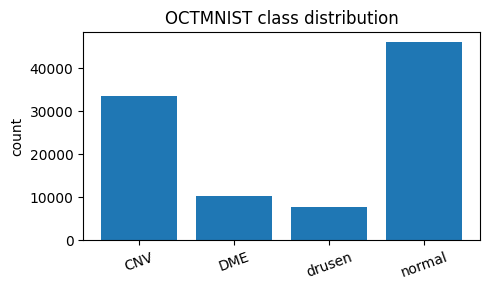

In [7]:
from medmnist import INFO
import medmnist

OCT_CLASSES = {0: "CNV", 1: "DME", 2: "drusen", 3: "normal"}
OCT_ROOT = DATA_DIR / "medmnist"; OCT_ROOT.mkdir(parents=True, exist_ok=True)
_octcls = getattr(medmnist, INFO["octmnist"]["python_class"])
_octtrain = _octcls(split="train", download=True, root=str(OCT_ROOT))
_octval = _octcls(split="val", download=True, root=str(OCT_ROOT))
oct_train_imgs, oct_train_lbl = _octtrain.imgs, _octtrain.labels.reshape(-1)
oct_val_imgs = _octval.imgs  # held-out real split for FID (not used in training)

# OCT-02 class distribution + real samples. Provenance fields are read from the
# installed medmnist INFO record rather than typed in, so they cannot drift.
counts = {OCT_CLASSES[i]: int((oct_train_lbl == i).sum()) for i in OCT_CLASSES}
print("class counts:", counts)
oct_info = {"source": "MedMNIST v2 OCTMNIST",
            "url": INFO["octmnist"].get("url"),
            "md5": INFO["octmnist"].get("MD5"),
            "license": INFO["octmnist"].get("license"),
            "medmnist_version": getattr(medmnist, "__version__", "unknown"),
            "split_sizes": {"train": int(len(oct_train_lbl)),
                            "val_holdout": int(len(oct_val_imgs))},
            "train_class_counts": counts}
json.dump(oct_info, open(METRIC_DIR / "octmnist_data.json", "w"), indent=2)
print("dataset record:", json.dumps({k: oct_info[k] for k in ("md5", "license", "medmnist_version")}))

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(list(counts), list(counts.values()), color="#1f77b4"); ax.set_ylabel("count")
ax.set_title("OCTMNIST class distribution"); plt.xticks(rotation=20)
fig.tight_layout(); fig.savefig(FIG_DIR / "octmnist_classes.png", dpi=150); plt.show()

oct_train = grayscale_to_tensor(oct_train_imgs, 32)
oct_loader = DataLoader(TensorDataset(oct_train, torch.from_numpy(oct_train_lbl.astype(np.int64))),
                        batch_size=128, shuffle=True, drop_last=True)

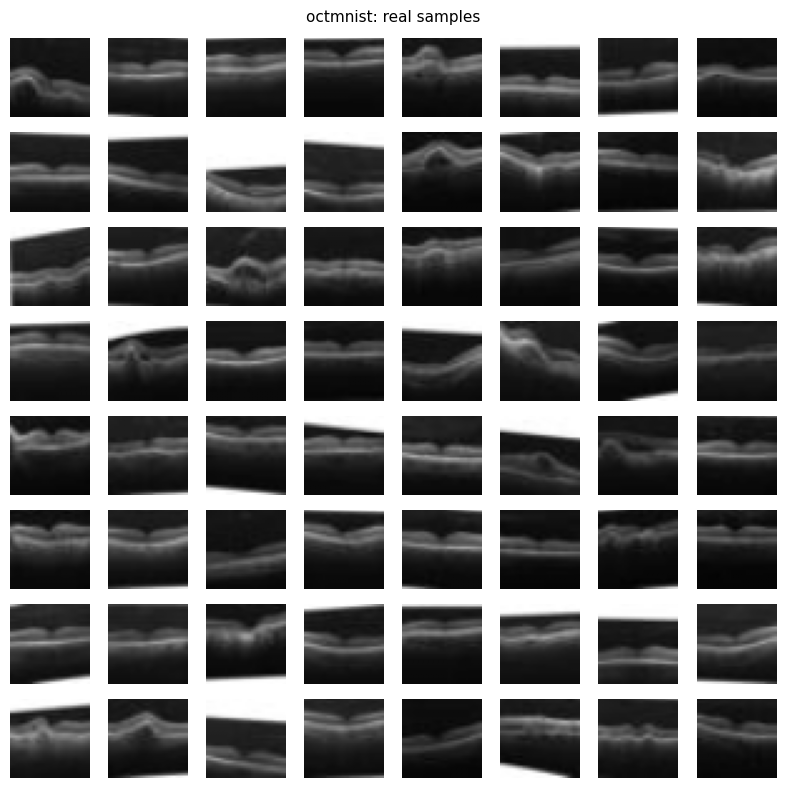

[octmnist] epoch 0/60 loss_d=0.594 loss_g=3.448
[octmnist] epoch 12/60 loss_d=0.494 loss_g=3.422
[octmnist] epoch 24/60 loss_d=0.474 loss_g=3.759
[octmnist] epoch 36/60 loss_d=0.407 loss_g=4.199
[octmnist] epoch 48/60 loss_d=0.407 loss_g=4.310
[octmnist] epoch 59/60 loss_d=0.423 loss_g=4.175
saved checkpoint: Outputs/checkpoints/octmnist_generator.pt


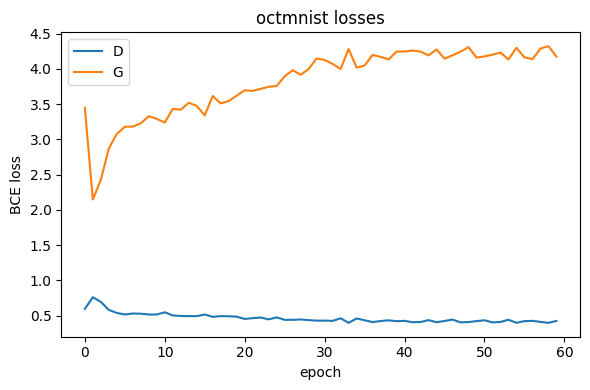

[octmnist] loss trend over 60 epochs: D 0.594 -> 0.423 (falling), G 3.448 -> 4.175 (rising)
[octmnist] final losses against the chance equilibrium of this loss construction (loss_d = summed real+fake BCE, so 2*ln2 = 1.386; loss_g = single BCE term, so ln2 = 0.693): D 0.423, G 4.175
[octmnist] REGIME VERDICT: discriminator-dominant (band +/-15% of equilibrium)


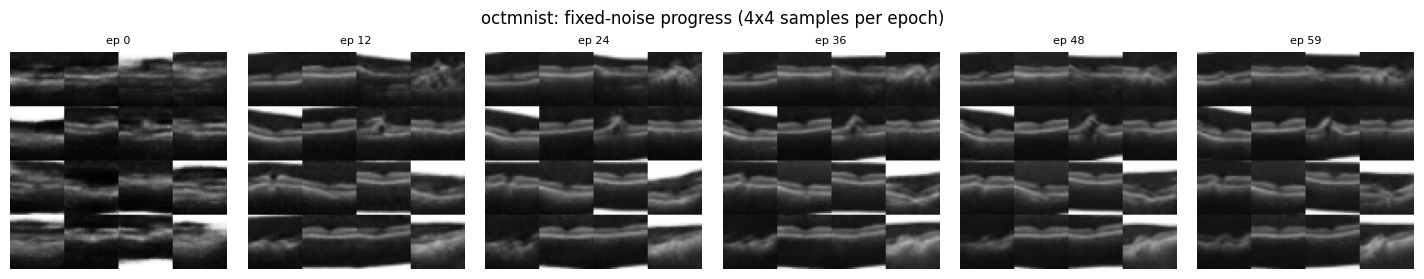

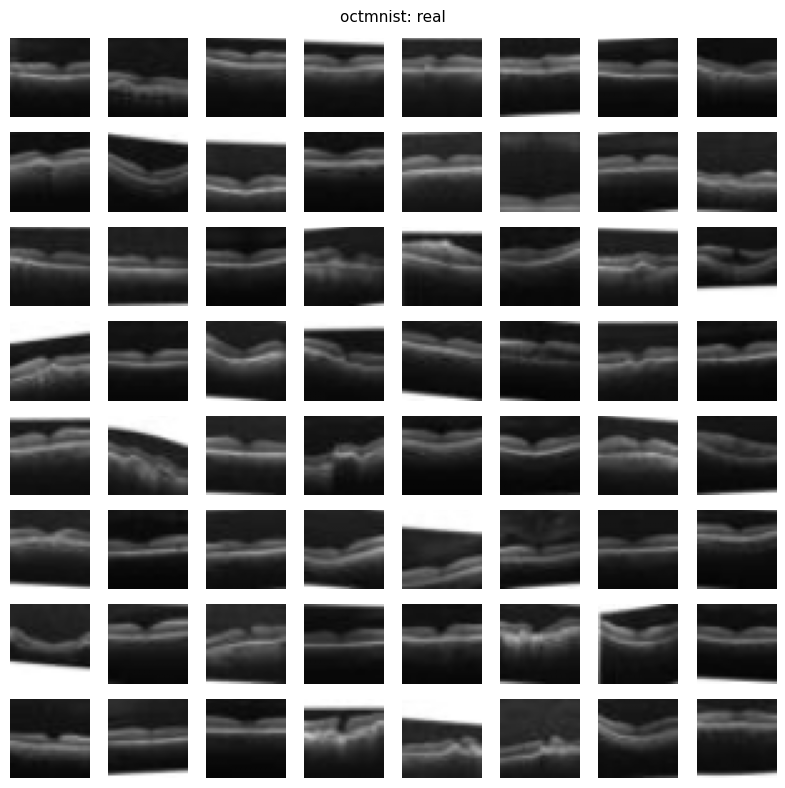

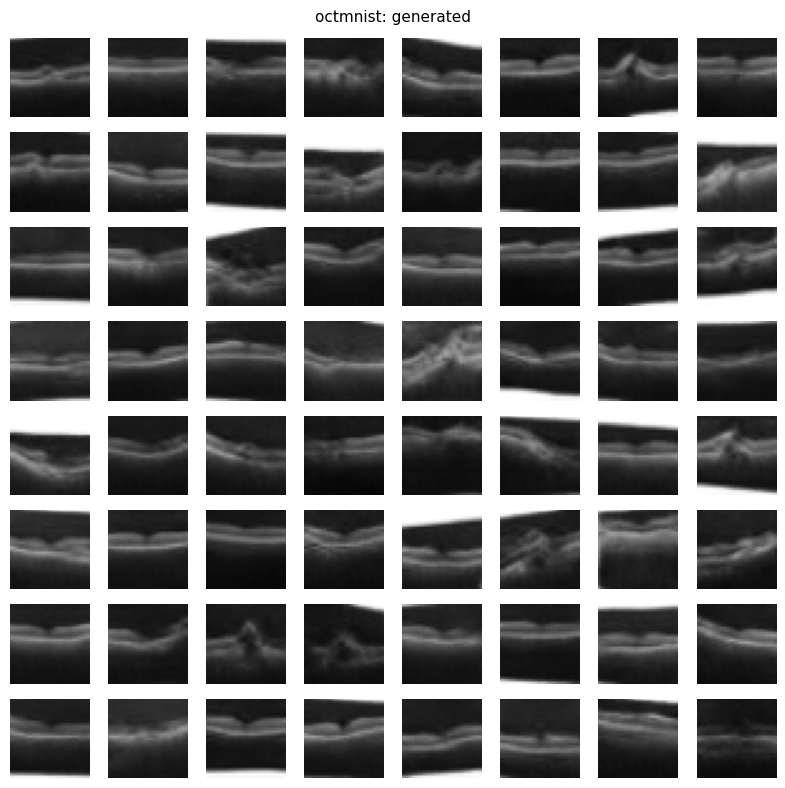

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth

{
  "sample_count": 2048,
  "method": "inception_v3_fid_torchmetrics_feature2048_heldout",
  "sample_selection": "first 64 of the fixed-noise draw, no manual selection",
  "feature_frechet_distance": 2.374033526457697,
  "feature_mmd_rbf": 0.036311948259076576,
  "feature_note": "discriminator GAP feature space (256-d), held-out real, relative score",
  "inception_fid": 34.66508102416992,
  "fid_extractor": "InceptionV3 (torchmetrics, ImageNet weights)",
  "fid_inputs": "grayscale->3ch, [0,255] uint8, resized to 299 internally",
  "fid_sample_count": 2048,
  "diversity": {
    "samples_compared": 1000,
    "train_reference_samples": 2000,
    "space": "flattened 32x32 pixels in [-1, 1]",
    "generated_mean_pairwise_distance": 12.695310941676178,
    "real_mean_pairwise_distance": 14.00650602311483,
    "diversity_ratio": 0.9063867120554693,
    "diversity_ratio_computable": true,
    "spread_verdict": "generated spread comparable to real",
    "generated_mean_nn_distance_to_train": 4.

In [8]:
oct_res = train_dcgan(oct_loader, "octmnist", epochs=60, real_grid=oct_train)
oct_trend = plot_losses(oct_res); plot_progress(oct_res)
oct_metrics = eval_dcgan(oct_res, grayscale_to_tensor(oct_val_imgs, 32), oct_train)

## How faithful are the generated OCT scans?

Resemblance. Judge the generated grid against the real grid printed directly
above it, not against a memory of what an OCT scan looks like. At 32x32 the real
images are already reduced to a bright, roughly horizontal retinal band over a
darker background with speckle. That coarse layout is the part a small DCGAN can
learn, and it is the part to check first: band position, band thickness, the
light/dark ordering of the layers, and the overall noise texture. The Inception
FID and the discriminator-feature Frechet distance printed above summarise the
same comparison over 2048 held-out real images and 2048 generated ones.

Artifacts and failure modes to look for. Transposed-convolution checkerboard
texture, over-smooth regions where the speckle has been averaged away, retinal
bands that break or run off the edge of the frame, and near-duplicate samples
across the grid. The four OCTMNIST classes are strongly imbalanced (the printed
class counts show it), and this model is unconditional, so it is free to
concentrate on the majority appearance and under-represent the rarer pathologies.
Nothing in the training objective penalises that, and neither FID nor the feature
distance separates it from a genuine overall improvement.

The near-duplicate case is the one that can be measured rather than eyeballed, so
the evaluation cell prints it. The mean pairwise pixel distance among generated
images is reported against the same statistic on held-out real images, and the
printed diversity verdict names which band the ratio falls in: a spread far below
the real one is what mode collapse looks like numerically, a spread modestly below
it is the milder loss of variety that an unconditional model on an imbalanced
dataset tends to produce, a comparable spread rules the failure out at this
resolution, and a spread above the real one means the generator is scattering
outside the data rather than concentrating on it. The same cell prints the mean
nearest-neighbour distance from generated images to the training split next to the
same distance for held-out real images, and names a memorisation verdict:
generated samples that sit closer to the training split than genuine unseen real
images do are the signature of copying, and that is the one reading that would
undermine every other number here. Take both directions from the printed
verdicts.

Training regime. The loss-trend line printed under the loss curve reports the
first and last epoch value and the direction of travel for both losses, compares
the final values against the chance equilibrium of this loss construction, and
names the regime. The equilibrium is not an arbitrary reference: the training loop
sums the real and fake discriminator terms, so a discriminator that has learned
nothing beyond guessing sits at 2*ln2, and the generator term sits at ln2. A
discriminator-dominant reading, its loss well under 2*ln2 while the generator loss
runs well over ln2, means the discriminator is separating real from generated
increasingly easily and the generator is pushing against a confident opponent
whose gradients grow less informative as training goes on. A generator-dominant
reading is the mirror image and on a DCGAN usually means the discriminator has
been outpaced rather than that the samples are good. A near-equilibrium reading is
the textbook healthy case, and a mixed reading means the run sits between them and
the loss curve on its own does not settle the question. The regime is a diagnostic
of the game, not of sample quality, so read it alongside the FID and the diversity
verdict rather than in place of them. Whatever the regime, a generator loss that
climbs steadily to the last epoch is not evidence of improvement, and the
final-epoch checkpoint is not guaranteed to be the best one. This run keeps the
final epoch as a predeclared rule rather than selecting the epoch with the best
FID, which would bias the reported number.

Uncertainty. Every figure here comes from one seed and one training run. FID
is itself a biased, sample-size-dependent estimate, and the extractor is an
ImageNet-trained Inception network whose features were never designed for small
single-channel medical scans, so the absolute value is only meaningful as a
relative comparison inside this notebook under this exact protocol.

Clinical status. The generated images are not diagnostic and carry no clinical
information. They are samples from a model fitted to a downsampled public
teaching dataset; they must not be used for training, validating or supporting any
diagnostic claim, and no statement here should be read as evidence that synthetic
OCT images are safe for clinical use.

## Can a tabular GAN synthesise CICIDS DoS flows?

Scope: the Wednesday working-hours capture, restricted to BENIGN and DoS
(Hulk, GoldenEye, slowloris, Slowhttptest); Heartbleed excluded and reported.

Data acquisition: the cell below auto-downloads the Wednesday CSV
(`Wednesday-workingHours.pcap_ISCX.csv`) from a public mirror into `data/` on
first run, and records the file size and SHA-256 of the copy actually used. If the
download is unavailable it falls back to a clearly labelled synthetic stand-in so
the notebook still runs; the self-check at the end flags that case rather than
letting it pass unnoticed.

Cleaning (CIC-02): strip column names, count and report infinite cells, missing
cells, non-finite rows and exact duplicate rows before dropping any of them, then
drop them. Leakage control (CIC-04): split first, then fit the zero-variance
filter, the scaler and the PCA on the training split only.

In [9]:
CICIDS_CSV = DATA_DIR / "Wednesday-workingHours.pcap_ISCX.csv"  # raw download, outside Outputs/
CICIDS_URL = "https://huggingface.co/datasets/c01dsnap/CIC-IDS2017/resolve/main/Wednesday-workingHours.pcap_ISCX.csv"

def _download_cicids(dst):
    dst = Path(dst)
    if dst.exists():
        return True
    dst.parent.mkdir(parents=True, exist_ok=True)
    try:
        print("Downloading CICIDS Wednesday CSV (~225 MB, one time)...")
        urllib.request.urlretrieve(CICIDS_URL, dst)
        return dst.exists()
    except Exception as e:
        print("auto-download failed:", e)
        return False

def _file_fingerprint(path):
    # Size and digest of the exact file used, so the run can be tied to one
    # version of the capture rather than to a file name.
    import hashlib
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return {"bytes": int(Path(path).stat().st_size), "sha256": h.hexdigest()}

def _load_cicids_dataframe():
    import pandas as pd
    _download_cicids(CICIDS_CSV)
    if CICIDS_CSV.exists():
        print("using local CSV:", CICIDS_CSV.name)
        return pd.read_csv(CICIDS_CSV, low_memory=False), True
    print("WARNING: no CSV available - using a SYNTHETIC stand-in (not for final results).")
    rng = np.random.default_rng(SEED); d = 20
    benign = rng.normal(0, 1, (1500, d)); dos = rng.normal(3, 1.5, (1500, d))
    df = pd.DataFrame(np.vstack([benign, dos]), columns=[f"f{i}" for i in range(d)])
    df["Label"] = ["BENIGN"] * 1500 + ["DoS Hulk"] * 1500
    return df, False

import pandas as pd
cic_df, cic_real = _load_cicids_dataframe()
cic_df.columns = [c.strip() for c in cic_df.columns]
label_col = "Label" if "Label" in cic_df.columns else cic_df.columns[-1]

# CIC-01 provenance record for whichever source was actually used.
cic_source = {"is_real_capture": bool(cic_real),
              "file": CICIDS_CSV.name if cic_real else "synthetic stand-in",
              "url": CICIDS_URL if cic_real else None,
              "access_conditions": "CIC-IDS2017 is released by the Canadian Institute for "
                                   "Cybersecurity for research use with attribution; the copy "
                                   "above is a public mirror of the Wednesday capture.",
              "rows_raw": int(len(cic_df)), "columns_raw": int(cic_df.shape[1])}
if cic_real:
    cic_source.update(_file_fingerprint(CICIDS_CSV))
json.dump(cic_source, open(METRIC_DIR / "cicids_source.json", "w"), indent=2)
print(json.dumps(cic_source, indent=2))

using local CSV: Wednesday-workingHours.pcap_ISCX.csv
{
  "is_real_capture": true,
  "file": "Wednesday-workingHours.pcap_ISCX.csv",
  "url": "https://huggingface.co/datasets/c01dsnap/CIC-IDS2017/resolve/main/Wednesday-workingHours.pcap_ISCX.csv",
  "access_conditions": "CIC-IDS2017 is released by the Canadian Institute for Cybersecurity for research use with attribution; the copy above is a public mirror of the Wednesday capture.",
  "rows_raw": 692703,
  "columns_raw": 79,
  "bytes": 225166395,
  "sha256": "893c27dc968bf7a8adef1689f90be55ca4a4dc3088fb63d6ff247ac56856df2a"
}

{
  "excluded_labels": {
    "Heartbleed": 11
  },
  "infinite_cells_before_drop": 1586,
  "missing_cells_before_drop": 1008,
  "rows_with_any_nonfinite_value_dropped": 1297,
  "duplicate_rows_dropped": 80914,
  "n_rows_used": 610481,
  "n_numeric_columns": 78,
  "benign": 416736,
  "dos": 193745
}


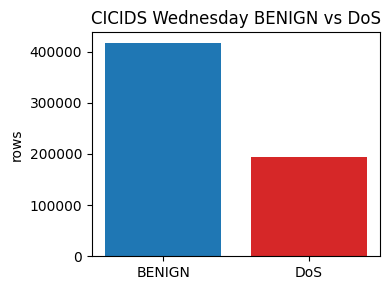

features kept after the training-split variance filter: 68 (dropped 10: ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate'])
first features: ['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min'] ...
split: 488384 train rows / 122097 test rows, train DoS share 0.317, test DoS share 0.317


In [10]:
# Restrict to BENIGN + DoS, clean, and build leakage-safe splits. Everything the
# cleaning removes is counted and printed before it is dropped (CIC-02), because
# a silent drop of a few hundred thousand cells is indistinguishable from a bug.
labels = cic_df[label_col].astype(str).str.strip()
keep = labels.eq("BENIGN") | labels.str.startswith("DoS")
excluded = {k: int(v) for k, v in labels[~keep].value_counts().items()}
cic_df2 = cic_df.loc[keep].copy(); labels = labels.loc[keep]

num = cic_df2.drop(columns=[label_col]).select_dtypes(include=[np.number]).copy()

def cell_diagnostics(frame):
    """Count infinite and missing cells one column at a time to keep memory flat."""
    n_inf = n_nan = 0
    for col in frame.columns:
        v = frame[col].to_numpy(dtype=np.float64)
        n_inf += int(np.isinf(v).sum()); n_nan += int(np.isnan(v).sum())
    return n_inf, n_nan

n_inf_cells, n_nan_cells = cell_diagnostics(num)
num.replace([np.inf, -np.inf], np.nan, inplace=True)
finite = num.notna().all(axis=1)
n_nonfinite_rows = int((~finite).sum())
num = num.loc[finite]; labels = labels.loc[finite]

comb = num.copy(); comb["__y__"] = labels.values
n_duplicate_rows = int(comb.duplicated().sum())  # counted before the drop
comb = comb.drop_duplicates()
y = (~comb.pop("__y__").eq("BENIGN")).astype(np.int64).to_numpy()
feature_names = list(comb.columns)
X = comb.to_numpy(np.float32)

clean_report = {
    "excluded_labels": excluded,
    "infinite_cells_before_drop": n_inf_cells,
    "missing_cells_before_drop": n_nan_cells,
    "rows_with_any_nonfinite_value_dropped": n_nonfinite_rows,
    "duplicate_rows_dropped": n_duplicate_rows,
    "n_rows_used": int(len(comb)),
    "n_numeric_columns": int(len(feature_names)),
    "benign": int((y == 0).sum()), "dos": int((y == 1).sum())}
print(json.dumps(clean_report, indent=2))

fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(["BENIGN", "DoS"], [clean_report["benign"], clean_report["dos"]], color=["#1f77b4", "#d62728"])
ax.set_ylabel("rows"); ax.set_title("CICIDS Wednesday BENIGN vs DoS"); fig.tight_layout()
fig.savefig(FIG_DIR / "cicids_balance.png", dpi=150); plt.show()

# Split first, then derive every preprocessing decision from the training split
# alone (CIC-04). The variance filter is a fitted decision like the scaler: run on
# the pooled data it lets the test rows influence which columns survive.
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
keep_cols = Xtr.var(axis=0) > 0
dropped_cols = [n for n, k in zip(feature_names, keep_cols) if not k]
feature_names = [n for n, k in zip(feature_names, keep_cols) if k]
Xtr = Xtr[:, keep_cols]; Xte = Xte[:, keep_cols]
scaler = StandardScaler().fit(Xtr)  # fit on train only
Xtr_s = scaler.transform(Xtr).astype(np.float32); Xte_s = scaler.transform(Xte).astype(np.float32)

clean_report.update({"train_rows": int(len(Xtr)), "test_rows": int(len(Xte)),
                     "zero_variance_columns_dropped_on_train": dropped_cols,
                     "n_features_used": len(feature_names),
                     "features_used": feature_names})
json.dump(clean_report, open(METRIC_DIR / "cicids_cleaning.json", "w"), indent=2)
print(f"features kept after the training-split variance filter: {len(feature_names)} "
      f"(dropped {len(dropped_cols)}: {dropped_cols})")
print("first features:", feature_names[:8], "...")
print(f"split: {len(Xtr)} train rows / {len(Xte)} test rows, "
      f"train DoS share {ytr.mean():.3f}, test DoS share {yte.mean():.3f}")

[cicids] epoch 0/150 loss_d=1.237 loss_g=0.945
[cicids] epoch 15/150 loss_d=1.012 loss_g=1.505
[cicids] epoch 30/150 loss_d=1.027 loss_g=1.466
[cicids] epoch 45/150 loss_d=1.045 loss_g=1.454
[cicids] epoch 60/150 loss_d=1.067 loss_g=1.418
[cicids] epoch 75/150 loss_d=1.086 loss_g=1.384
[cicids] epoch 90/150 loss_d=1.098 loss_g=1.366
[cicids] epoch 105/150 loss_d=1.112 loss_g=1.343
[cicids] epoch 120/150 loss_d=1.129 loss_g=1.314
[cicids] epoch 135/150 loss_d=1.135 loss_g=1.291
[cicids] epoch 149/150 loss_d=1.140 loss_g=1.276
saved checkpoint: Outputs/checkpoints/cicids_generator.pt


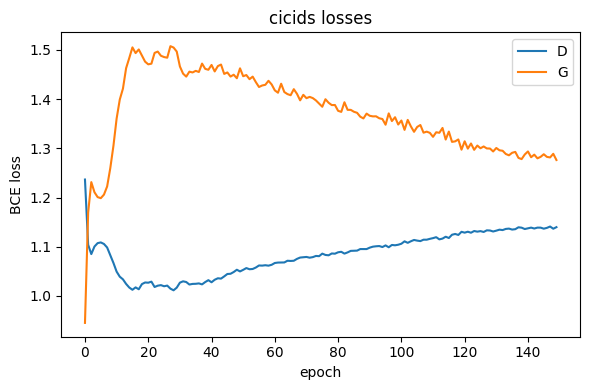

[cicids] loss trend over 150 epochs: D 1.237 -> 1.140 (falling), G 0.945 -> 1.276 (rising)
[cicids] final losses against the chance equilibrium of this loss construction (loss_d = summed real+fake BCE, so 2*ln2 = 1.386; loss_g = single BCE term, so ln2 = 0.693): D 1.140, G 1.276
[cicids] REGIME VERDICT: discriminator-dominant (band +/-15% of equilibrium)


In [11]:
class TabG(nn.Module):
    """Generator for tabular feature vectors: latent noise -> one standardised row."""
    def __init__(self, latent, out, h=128):
        super().__init__(); self.latent = latent
        self.net = nn.Sequential(nn.Linear(latent, h), nn.BatchNorm1d(h), nn.ReLU(True),
                                 nn.Linear(h, h*2), nn.BatchNorm1d(h*2), nn.ReLU(True),
                                 nn.Linear(h*2, out))
    def forward(self, z): return self.net(z)

class TabD(nn.Module):
    """Discriminator over feature vectors; dropout keeps it from winning immediately."""
    def __init__(self, inp, h=128, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(inp, h*2), nn.LeakyReLU(0.2, True), nn.Dropout(dropout),
                                 nn.Linear(h*2, h), nn.LeakyReLU(0.2, True), nn.Dropout(dropout),
                                 nn.Linear(h, 1), nn.Sigmoid())
    def forward(self, x): return self.net(x)

def train_cicids(Xtr_s, epochs=150, latent=32, h=128, lr=2e-4, beta1=0.5, smoothing=0.1, batch=256):
    # No output activation: the target is standardised, so the generator must be
    # free to emit values on both sides of zero. Domain validity is checked after
    # inverse-transforming back to raw units rather than clamped here (CIC-08).
    set_seed()
    if QUICK_MODE: epochs = 10
    nf = Xtr_s.shape[1]
    loader = DataLoader(TensorDataset(torch.from_numpy(Xtr_s)), batch_size=batch, shuffle=True, drop_last=True)
    G = TabG(latent, nf, h).to(DEVICE); D = TabD(nf, h).to(DEVICE)
    crit = nn.BCELoss()
    optG = torch.optim.Adam(G.parameters(), lr=lr, betas=(beta1, 0.999))
    optD = torch.optim.Adam(D.parameters(), lr=lr, betas=(beta1, 0.999))
    hist = []
    for ep in range(epochs):
        ed = eg = nb = 0
        for (real,) in loader:
            real = real.to(DEVICE); cur = real.shape[0]
            rl, fl = real_fake_labels(cur, DEVICE, smoothing)
            optD.zero_grad()
            loss_dr = crit(D(real), rl)
            z = torch.randn(cur, latent, device=DEVICE); fake = G(z)
            loss_d = loss_dr + crit(D(fake.detach()), fl); assert_finite(loss_d, "loss_d")
            loss_d.backward(); optD.step()
            for p in D.parameters(): p.requires_grad_(False)
            optG.zero_grad(); loss_g = crit(D(fake), rl); assert_finite(loss_g, "loss_g")
            loss_g.backward(); optG.step()
            for p in D.parameters(): p.requires_grad_(True)
            ed += loss_d.item(); eg += loss_g.item(); nb += 1
        hist.append((ed / nb, eg / nb))
        if ep % max(1, epochs // 10) == 0 or ep == epochs - 1:
            print(f"[cicids] epoch {ep}/{epochs} loss_d={ed/nb:.3f} loss_g={eg/nb:.3f}")
    hist = np.array(hist)
    ckpt = CKPT_DIR / "cicids_generator.pt"
    config = {"tag": "cicids", "latent": latent, "hidden": h, "n_features": nf,
              "epochs": epochs, "lr": lr, "beta1": beta1, "label_smoothing": smoothing,
              "batch_size": batch, "seed": SEED, "optimiser": "Adam", "loss": "BCE"}
    torch.save({"generator_state": G.state_dict(), "latent": latent,
                "n_features": nf, "config": config}, ckpt)
    np.savetxt(METRIC_DIR / "cicids_losses.csv", hist,
               delimiter=",", header="loss_d,loss_g", comments="")
    json.dump(config, open(METRIC_DIR / "cicids_config.json", "w"), indent=2)
    print("saved checkpoint:", os.path.relpath(ckpt, _ROOT))
    return {"G": G, "hist": hist, "latent": latent, "ckpt": ckpt, "tag": "cicids"}

cic_res = train_cicids(Xtr_s)
with open(CKPT_DIR / "cicids_scaler.pkl", "wb") as fh:
    pickle.dump(scaler, fh)  # the fitted scaler is needed to read generated rows back
cic_trend = plot_losses(cic_res)

## How is the CICIDS fit measured?

Samples are drawn from the reloaded generator checkpoint. PCA of real (held-out)
versus generated vectors, with PCA fit on the real training split only; the view is
clipped to the 1st-99th percentile of the real projection because its tails
otherwise squash the rest onto a line, and the fraction of points falling outside
the view is printed. Because a clipped view cannot show whether the generated
cloud runs past the real one or sits inside it, the cell also prints the full real
and generated range on each component and a named extent verdict. Every metric is
computed on all samples, not on the cropped view.

Quantitative alignment (CIC-08): mean per-feature 1D Wasserstein, correlation-matrix
Frobenius error, MMD, and a valid-domain check that inverse-transforms the
generated rows back to raw units and measures how often they break non-negativity
in features that are never negative in the training data, with a per-feature
breakdown. t-SNE is a qualitative aid only.

{
  "sample_count": 2000,
  "method": "standardised-space mean_feature_wasserstein + correlation_frobenius + mmd_rbf",
  "mean_feature_wasserstein": 0.1822942201438216,
  "correlation_frobenius_error": 11.174649422975438,
  "mmd_rbf": 0.03650576337788891,
  "domain_validity": {
    "nonnegative_features_checked": 56,
    "features_total": 68,
    "violating_cell_fraction": 0.24266964285714285,
    "rows_with_any_violation_fraction": 1.0,
    "clean_features": 0,
    "worst_features": [
      {
        "feature": "SYN Flag Count",
        "negative_rate": 0.6095
      },
      {
        "feature": "Bwd IAT Min",
        "negative_rate": 0.591
      },
      {
        "feature": "Fwd PSH Flags",
        "negative_rate": 0.5855
      },
      {
        "feature": "ACK Flag Count",
        "negative_rate": 0.584
      },
      {
        "feature": "PSH Flag Count",
        "negative_rate": 0.4755
      },
      {
        "feature": "ECE Flag Count",
        "negative_rate": 0.474
      },


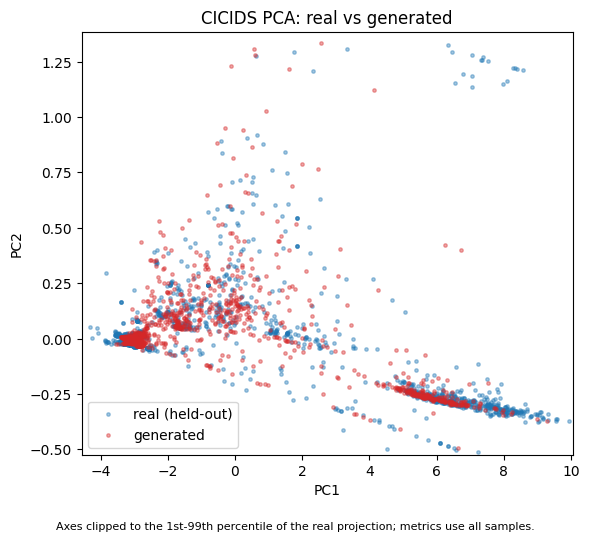

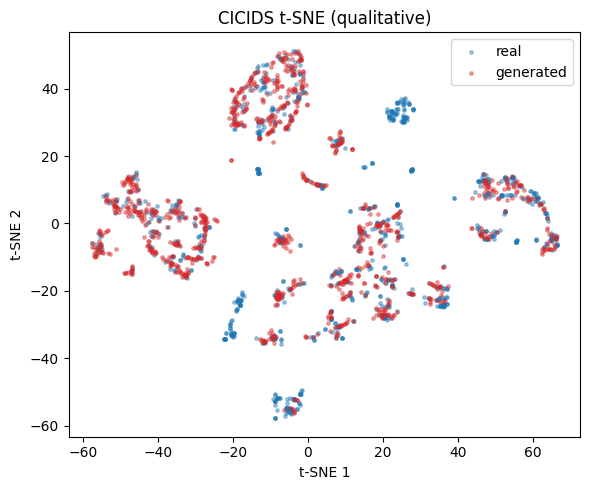

In [12]:
# Reload the saved generator so the evaluation exercises the checkpoint the folder
# actually ships rather than the in-memory model.
set_seed()
_blob = torch.load(cic_res["ckpt"], map_location=DEVICE)
cic_G = TabG(_blob["latent"], _blob["n_features"], _blob.get("config", {}).get("hidden", 128)).to(DEVICE)
cic_G.load_state_dict(_blob["generator_state"]); cic_G.eval()

n = min(2000, len(Xte_s))
with torch.no_grad():
    gen = cic_G(torch.randn(n, _blob["latent"], device=DEVICE)).cpu().numpy()
real_te = Xte_s[:n]

def corr_err(a, b):
    """Frobenius distance between the two feature correlation matrices."""
    ca = np.nan_to_num(np.corrcoef(a, rowvar=False)); cb = np.nan_to_num(np.corrcoef(b, rowvar=False))
    return float(np.linalg.norm(ca - cb, ord="fro"))

def domain_validity(gen_std, train_raw, names, scaler):
    """Fraction of generated cells that break a non-negativity constraint.

    Flow features such as packet counts, byte totals and durations cannot be
    negative. The generator has no output constraint enforcing that, so the check
    inverse-transforms the generated rows back to raw units and measures how often
    the rule is broken. Features that are non-negative across the whole training
    split are the ones held to the rule; the per-feature breakdown makes the single
    aggregate number interpretable instead of a bare percentage.
    """
    gen_raw = scaler.inverse_transform(gen_std)
    mask = train_raw.min(axis=0) >= 0
    viol = gen_raw[:, mask] < 0
    rates = viol.mean(axis=0)
    checked = [nm for nm, k in zip(names, mask) if k]
    worst = sorted(zip(checked, rates.tolist()), key=lambda t: -t[1])[:10]
    return {"nonnegative_features_checked": int(mask.sum()),
            "features_total": int(len(names)),
            "violating_cell_fraction": float(viol.mean()),
            "rows_with_any_violation_fraction": float(viol.any(axis=1).mean()),
            "clean_features": int((rates == 0).sum()),
            "worst_features": [{"feature": f, "negative_rate": float(r)} for f, r in worst]}

cic_metrics = {"sample_count": int(n),
    "method": "standardised-space mean_feature_wasserstein + correlation_frobenius + mmd_rbf",
    "mean_feature_wasserstein": float(np.mean([wasserstein_distance(real_te[:, d], gen[:, d]) for d in range(real_te.shape[1])])),
    "correlation_frobenius_error": corr_err(real_te, gen),
    "mmd_rbf": mmd_rbf(real_te, gen),
    "domain_validity": domain_validity(gen, Xtr, feature_names, scaler)}
json.dump(cic_metrics, open(METRIC_DIR / "cicids_eval.json", "w"), indent=2)
print(json.dumps(cic_metrics, indent=2))

dv = cic_metrics["domain_validity"]
print(f"\nCIC-08 domain check: {dv['violating_cell_fraction']:.4%} of generated cells are negative "
      f"in features that are never negative in training data "
      f"({dv['nonnegative_features_checked']} of {dv['features_total']} features held to the rule); "
      f"{dv['rows_with_any_violation_fraction']:.2%} of generated rows contain at least one such value; "
      f"{dv['clean_features']} of those features are never violated.")
print("highest per-feature negative rates:")
for row in dv["worst_features"]:
    print(f"  {row['feature'][:44]:44s} {row['negative_rate']:.4%}")

pca = PCA(n_components=2, random_state=SEED).fit(Xtr_s)  # fit on train only
r2 = pca.transform(real_te); g2 = pca.transform(gen)
# A handful of extreme real flows stretch the PCA axes by orders of magnitude and
# flatten everything else onto a line. The view is clipped to the 1st-99th
# percentile of the real projection so the overlap is judgeable; every metric
# above is computed on all samples, none of them on this cropped view.
lo = np.percentile(r2, 1, axis=0); hi = np.percentile(r2, 99, axis=0)
pad = 0.08 * np.maximum(hi - lo, 1e-9)
xlim, ylim = (lo[0] - pad[0], hi[0] + pad[0]), (lo[1] - pad[1], hi[1] + pad[1])
outside = {"real": float(((r2[:, 0] < xlim[0]) | (r2[:, 0] > xlim[1]) |
                          (r2[:, 1] < ylim[0]) | (r2[:, 1] > ylim[1])).mean()),
           "generated": float(((g2[:, 0] < xlim[0]) | (g2[:, 0] > xlim[1]) |
                               (g2[:, 1] < ylim[0]) | (g2[:, 1] > ylim[1])).mean())}
print(f"\nPCA view clipped to the 1st-99th percentile of the real projection; "
      f"points outside the view: real {outside['real']:.2%}, generated {outside['generated']:.2%}")

# A clipped overlap plot cannot say whether the generated cloud runs past the real
# one or sits inside it, and those two failures have different causes and
# different fixes. The extent is therefore decided here from the full, unclipped
# projections and printed as a named verdict per component, so the discussion
# reads a result instead of asserting one.
pca_extent = {}
for _k, _comp in enumerate(("PC1", "PC2")):
    _rlo, _rhi = float(r2[:, _k].min()), float(r2[:, _k].max())
    _glo, _ghi = float(g2[:, _k].min()), float(g2[:, _k].max())
    _out_n = int(((g2[:, _k] < _rlo) | (g2[:, _k] > _rhi)).sum())
    _out_frac = _out_n / len(g2)
    _span = (_ghi - _glo) / (_rhi - _rlo) if _rhi > _rlo else float("nan")
    if not np.isfinite(_span):
        _verdict = "not computable (real range is degenerate)"
    elif _span > 1.10:
        _verdict = "generated exceeds real range"
    elif _span < 0.90:
        _verdict = "generated falls short of real range"
    elif _out_frac > 0.05:
        # Comparable total span but a substantial share of points beyond the real
        # support still means the generator is emitting values the data never
        # reaches, so it is reported as an excess rather than as a match.
        _verdict = "generated exceeds real range"
    else:
        _verdict = "comparable extent"
    pca_extent[_comp] = {"real_min": _rlo, "real_max": _rhi,
                         "generated_min": _glo, "generated_max": _ghi,
                         "generated_span_over_real_span": float(_span),
                         "generated_points_outside_real_range": _out_n,
                         "generated_fraction_outside_real_range": float(_out_frac),
                         "verdict": _verdict}
cic_metrics["pca_extent"] = pca_extent
json.dump(cic_metrics, open(METRIC_DIR / "cicids_eval.json", "w"), indent=2)

print("\nCIC-07 extent of the generated projection against the real one "
      "(full projections, not the clipped view):")
for _comp, _e in pca_extent.items():
    print(f"  {_comp}: real [{_e['real_min']:.3f}, {_e['real_max']:.3f}] "
          f"generated [{_e['generated_min']:.3f}, {_e['generated_max']:.3f}] "
          f"span ratio {_e['generated_span_over_real_span']:.3f}; "
          f"{_e['generated_points_outside_real_range']} of {len(g2)} generated points "
          f"({_e['generated_fraction_outside_real_range']:.2%}) outside the real range")
    print(f"  {_comp} EXTENT VERDICT: {_e['verdict']}")

fig, ax = plt.subplots(figsize=(6, 5.4))
ax.scatter(r2[:, 0], r2[:, 1], s=6, alpha=0.4, label="real (held-out)", color="#1f77b4")
ax.scatter(g2[:, 0], g2[:, 1], s=6, alpha=0.4, label="generated", color="#d62728")
ax.set_xlim(*xlim); ax.set_ylim(*ylim)
ax.set_title("CICIDS PCA: real vs generated"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend()
fig.text(0.5, 0.01, "Axes clipped to the 1st-99th percentile of the real projection; "
                    "metrics use all samples.", ha="center", fontsize=8)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(FIG_DIR / "cicids_pca.png", dpi=150); plt.show()

# t-SNE (qualitative aid only, not a score)
from sklearn.manifold import TSNE
cap = min(1000, n)
emb = TSNE(n_components=2, init="pca", random_state=SEED,
           perplexity=30).fit_transform(np.vstack([real_te[:cap], gen[:cap]]))
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(emb[:cap, 0], emb[:cap, 1], s=6, alpha=0.4, label="real", color="#1f77b4")
ax.scatter(emb[cap:, 0], emb[cap:, 1], s=6, alpha=0.4, label="generated", color="#d62728")
ax.set_title("CICIDS t-SNE (qualitative)"); ax.set_xlabel("t-SNE 1"); ax.set_ylabel("t-SNE 2"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "cicids_tsne.png", dpi=150); plt.show()

## What does the CICIDS GAN get right and wrong?

Fidelity. Three printed numbers describe different parts of the fit. The mean
per-feature Wasserstein distance is a marginal check: it says how far each
generated column sits from the corresponding real column, one feature at a time,
and it is blind to the joint structure. The correlation Frobenius error covers
exactly what the marginals miss, the pairwise relationships between features; flow
features are heavily coupled (packet counts, byte totals and durations move
together), so a model can match every marginal and still produce rows that no real
capture would contain. MMD looks at the joint distribution through a kernel and is
the closest single summary, but it is computed on a capped subsample and depends
on the bandwidth heuristic, so it is a relative score inside this notebook rather
than an absolute one. The PCA panel is the visual counterpart, with the caveat
printed under it: the axes are clipped to the central 99 percent of the real
projection because its tails otherwise compress everything onto a line, and the
reported fractions say how much of each set falls outside the view.

A clipped panel is exactly the wrong thing to read a direction off, so the extent
of the generated projection is decided from the full projections and printed as a
verdict on each component. The two possible failures are not variations of one
problem. A generated set that exceeds the real range is over-dispersed: the
generator emits standardised values through a linear output layer with nothing
bounding it, the extreme tail of the real data is thin enough to carry almost no
training signal, and the model extrapolates past it. The remedy there is on the
output side, through an output transform, a tail-aware feature transform such as
a quantile or log mapping before standardisation, or an explicit range penalty. A
generated set that falls short of the real range is the opposite problem, missing
support: whole regions of real traffic are never produced at all, which on this
subset most plausibly means the generator has settled on the dominant traffic
pattern and dropped the rest. The remedy there is on the modelling side, through
conditioning on the label, resampling the training rows, or a loss less prone to
collapse than the saturating BCE game. A comparable extent means neither failure
dominates on that component and the fit has to be judged from the distance metrics
instead. Note also that a verdict can differ between PC1 and PC2, since the two
components carry different mixtures of features.

The t-SNE panel is a qualitative aid only. Its geometry depends on perplexity and
initialisation and it is not used as a score.

Domain validity. The generator emits standardised values with no output
constraint, so nothing forces it to respect the fact that packet counts, byte
totals and durations cannot be negative. The domain check measures that directly
after inverse-transforming back to raw units, and reports both the cell-level rate
and the share of rows containing at least one impossible value, with the worst
features listed. This matters more than the distance metrics for any downstream
use: a row can sit close to the real distribution in a kernel sense and still be
structurally invalid.

Privacy. No privacy claim is made or supported here. This GAN was trained
without any formal privacy mechanism, and nothing in the evaluation tests for
memorisation, nearest-neighbour leakage or membership inference. A generative
model can reproduce training rows closely, and the metrics used here would not
detect it; a low distance score is in fact equally consistent with memorisation
and with generalisation. Synthetic network traffic must not be treated as
anonymised or as safe to release on the strength of this work.

Utility. Likewise untested. The obvious use for synthetic flow records is
augmenting or replacing training data for an intrusion detector, and the standard
way to evaluate that is train-on-synthetic, test-on-real: fit a classifier on
generated rows and score it against the held-out real split, against a baseline
fitted on real data. That experiment is not run here, so no claim is made that
these rows are operationally useful.

Failure modes and limitations. The class balance printed earlier gives the
BENIGN and DoS row counts for the subset actually used, and the bar chart shows
the same thing; read those before assuming anything about which class dominates.
Whichever does, this GAN is unconditional, so it is free to concentrate on the
more common traffic pattern and to under-produce the other, and none of the
reported distance metrics separates that from a good overall fit. The extent
verdict on the PCA components is the closest thing here to a check on it. The
scope is one day of one capture (Wednesday BENIGN plus DoS), so nothing here
generalises to other attack families or to other days. Rows containing non-finite values and exact duplicates
were removed before training, which changes the modelled distribution relative to
the raw capture; the counts are printed so the effect is visible. Finally, this is
one seed and one run, and GAN training on tabular data is unstable enough that the
numbers should be read with that in mind.

## Can the DCGAN draw birthday cakes?

QuickDraw "birthday cake" numpy_bitmap: 28x28 grayscale sketches. Downloaded from
the official Google bucket, resized to 32x32, scaled to [-1, 1]. Reuses the shared
DCGAN. Requirements: real-sketch exploration (QD-02), train + losses + epoch
progress (QD-03/04), generated samples (QD-05), visual and quantitative
comparison (QD-06/07).

quickdraw birthday cake bitmaps: (60000, 28, 28) of 144982 available
value range: 0 to 255 | mean ink fraction: 0.3310593962585034

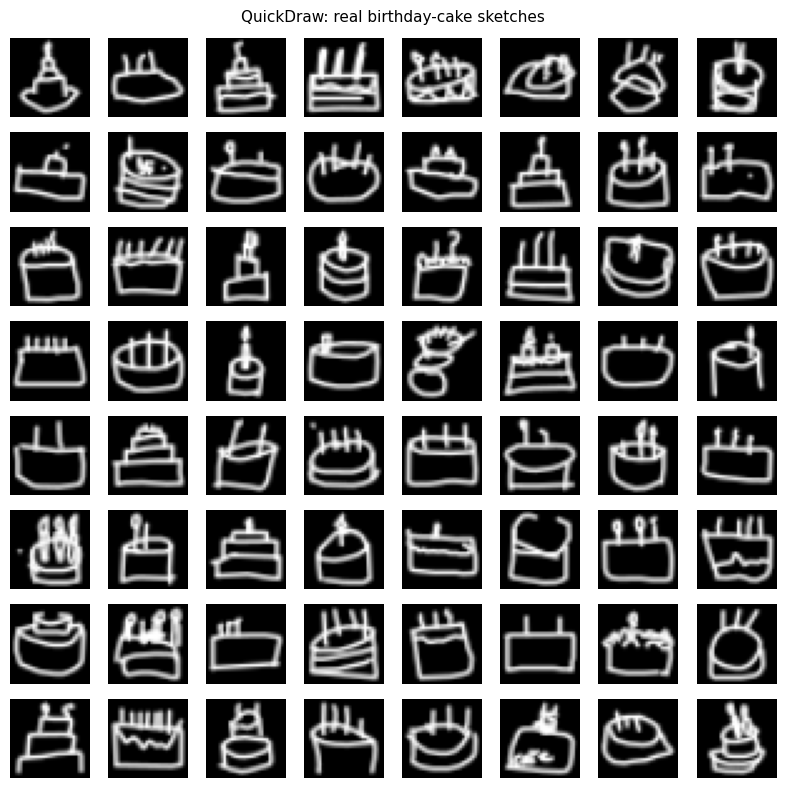

In [13]:
QD_CATEGORY = "birthday cake"
QD_URL = ("https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/"
          + urllib.parse.quote(QD_CATEGORY) + ".npy")
QD_NPY = DATA_DIR / "birthday_cake.npy"  # raw download, outside Outputs/
if not QD_NPY.exists():
    print("downloading", QD_URL); urllib.request.urlretrieve(QD_URL, QD_NPY)

qd = np.load(QD_NPY)
if qd.ndim == 2: qd = qd.reshape(-1, 28, 28)
qd_available = int(len(qd))
qd = qd[:60000].astype(np.uint8)
print("quickdraw birthday cake bitmaps:", qd.shape, "of", qd_available, "available")
print("value range:", int(qd.min()), "to", int(qd.max()),
      "| mean ink fraction:", float((qd > 0).mean()))

# Held-out split: train on the first 50k, evaluate FID against the last 10k that
# the generator never sees.
qd_train_t = grayscale_to_tensor(qd[:50000], 32)
qd_holdout_t = grayscale_to_tensor(qd[50000:], 32)
qd_loader = DataLoader(TensorDataset(qd_train_t, torch.zeros(len(qd_train_t), dtype=torch.long)),
                       batch_size=128, shuffle=True, drop_last=True)
json.dump({"source": "Google Quick, Draw! numpy_bitmap", "category": QD_CATEGORY,
           "url": QD_URL, "license": "CC BY 4.0",
           "bitmaps_available": qd_available, "bitmaps_used": int(len(qd)),
           "train": int(len(qd_train_t)), "holdout": int(len(qd_holdout_t)),
           "image_size": 32, "value_range_raw": [int(qd.min()), int(qd.max())]},
          open(METRIC_DIR / "quickdraw_data.json", "w"), indent=2)

# QD-02 exploration grid, saved under its own name so the training cell's real
# grid does not overwrite it.
show_grid(qd_train_t[:64], "QuickDraw: real birthday-cake sketches",
          save=FIG_DIR / "quickdraw_real_samples.png")

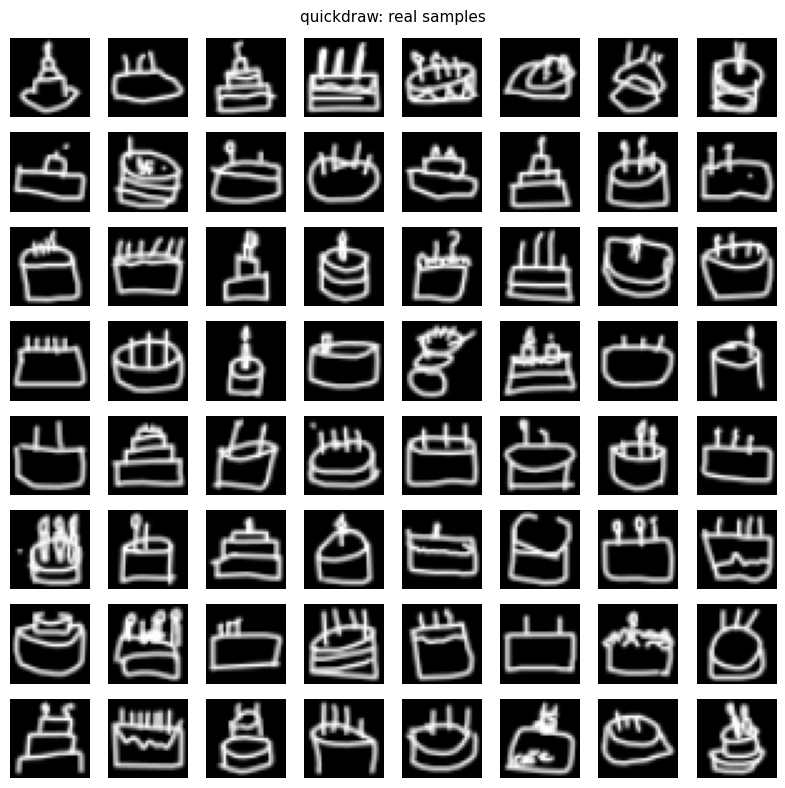

[quickdraw] epoch 0/40 loss_d=0.526 loss_g=3.791
[quickdraw] epoch 8/40 loss_d=0.541 loss_g=3.018
[quickdraw] epoch 16/40 loss_d=0.471 loss_g=3.795
[quickdraw] epoch 24/40 loss_d=0.401 loss_g=4.364
[quickdraw] epoch 32/40 loss_d=0.455 loss_g=4.042
[quickdraw] epoch 39/40 loss_d=0.363 loss_g=4.651
saved checkpoint: Outputs/checkpoints/quickdraw_generator.pt


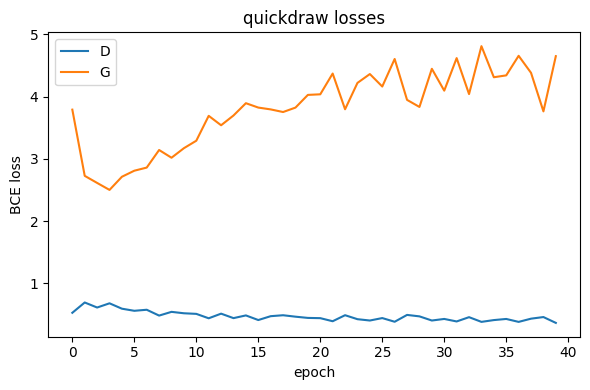

[quickdraw] loss trend over 40 epochs: D 0.526 -> 0.363 (falling), G 3.791 -> 4.651 (rising)
[quickdraw] final losses against the chance equilibrium of this loss construction (loss_d = summed real+fake BCE, so 2*ln2 = 1.386; loss_g = single BCE term, so ln2 = 0.693): D 0.363, G 4.651
[quickdraw] REGIME VERDICT: discriminator-dominant (band +/-15% of equilibrium)


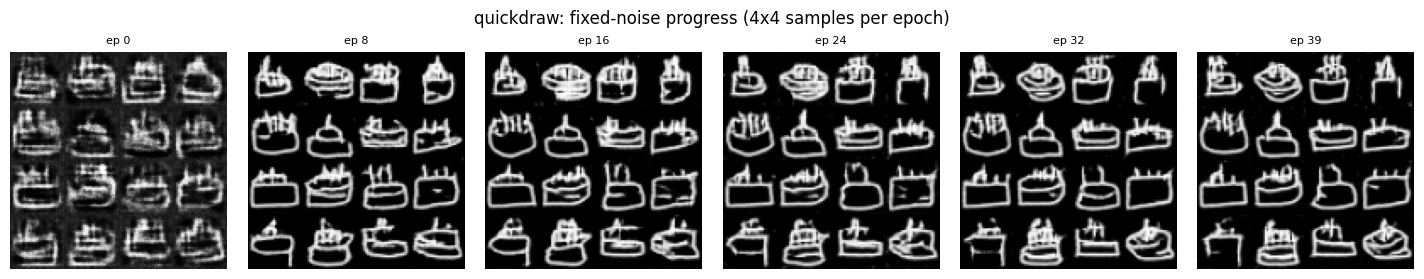

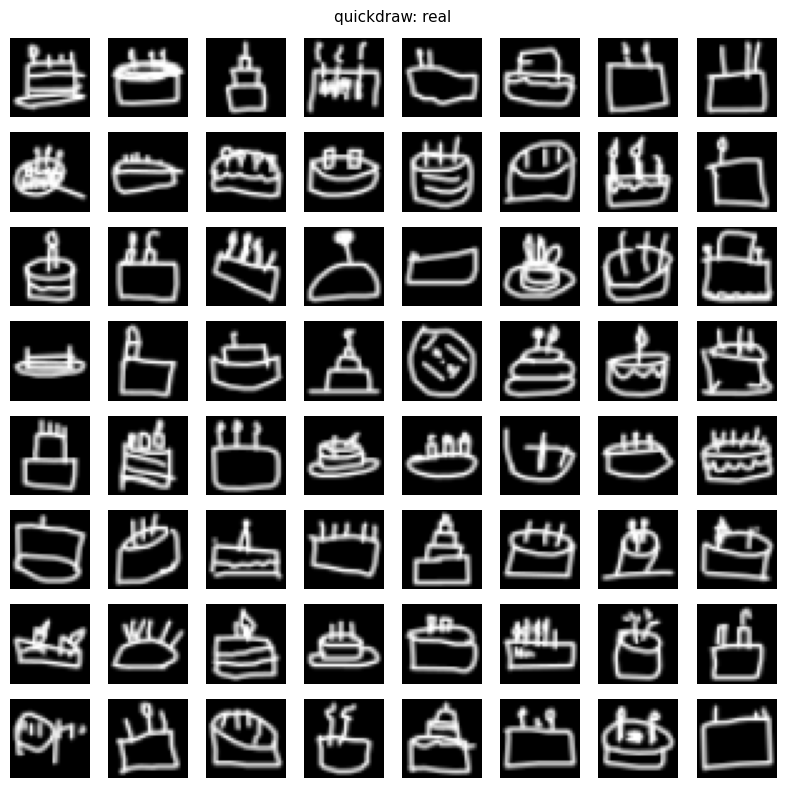

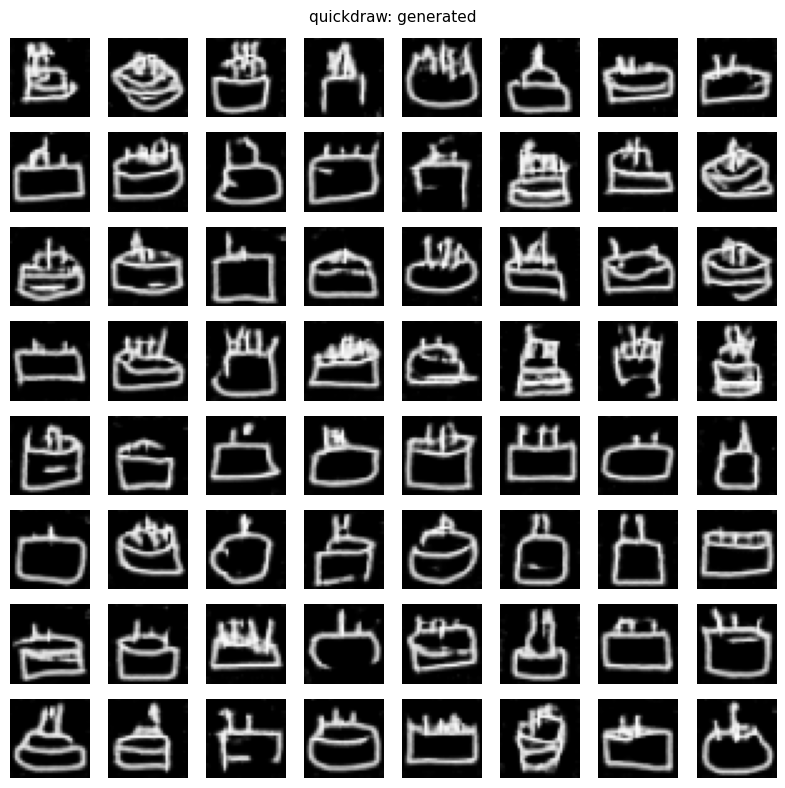

{
  "sample_count": 2048,
  "method": "inception_v3_fid_torchmetrics_feature2048_heldout",
  "sample_selection": "first 64 of the fixed-noise draw, no manual selection",
  "feature_frechet_distance": 4.9605571552726255,
  "feature_mmd_rbf": 0.14687555421125453,
  "feature_note": "discriminator GAP feature space (256-d), held-out real, relative score",
  "inception_fid": 29.131839752197266,
  "fid_extractor": "InceptionV3 (torchmetrics, ImageNet weights)",
  "fid_inputs": "grayscale->3ch, [0,255] uint8, resized to 299 internally",
  "fid_sample_count": 2048,
  "diversity": {
    "samples_compared": 1000,
    "train_reference_samples": 2000,
    "space": "flattened 32x32 pixels in [-1, 1]",
    "generated_mean_pairwise_distance": 23.47787312698864,
    "real_mean_pairwise_distance": 23.980915782142343,
    "diversity_ratio": 0.9790232091333101,
    "diversity_ratio_computable": true,
    "spread_verdict": "generated spread comparable to real",
    "generated_mean_nn_distance_to_train": 1

In [14]:
qd_res = train_dcgan(qd_loader, "quickdraw", epochs=40, real_grid=qd_train_t)
qd_trend = plot_losses(qd_res); plot_progress(qd_res)
qd_metrics = eval_dcgan(qd_res, qd_holdout_t, qd_train_t)

## Are the generated sketches varied and sharp?

Realism. A birthday-cake doodle is a sparse binary line drawing, not a texture,
so the useful test is structural: does the sample have a closed cake body, a
plausible base line, and candle-like strokes on top, drawn with strokes of roughly
the right thickness? Blurred grey strokes are the characteristic failure of a
pixel-space GAN on sketch data, because the model can lower its loss by hedging
between two plausible stroke positions instead of committing to one. Compare the
generated grid directly against the real grid printed above it; the two are drawn
under the same preprocessing and at the same size.

Diversity and mode collapse. This dataset is drawn by many people in twenty
seconds each, so genuine real variation is very wide: cakes with one candle and
with many, tall cakes, flat cakes, cakes drawn as a single outline. A generator
that produces one canonical cake has lost most of that variation even if its FID
looks reasonable, because FID is computed against a large held-out sample and is
only partly sensitive to lost diversity. The claim is therefore measured rather
than asserted. The evaluation cell prints the mean pairwise pixel distance among
generated sketches against the same statistic on held-out real sketches, and names
a diversity verdict from the ratio. A ratio far below one is collapse: the
generator is producing near copies of a single sketch from different latent codes.
A ratio moderately below one is the partial version, where several shapes survive
but the rarer drawing styles have been dropped. A ratio near one says the spread
matches the data at pixel level, which does not by itself prove the shapes are
right but does rule collapse out. A ratio above one means the samples are more
scattered than the data, which on sparse line art usually means noise rather than
extra variety. The progress panel is the visual counterpart: it decodes the same
fixed noise at each snapshot epoch and shows sixteen samples per panel, so tiles
converging on one another across panels is collapse happening during training
rather than at the end.

Sketch complexity. Two effects work against this model. The bitmaps are almost
entirely background, so the pixel-level objective is dominated by empty space and
the model is rewarded for getting the background right before the strokes. And
resizing 28x28 bitmaps up to 32x32 with bilinear interpolation softens the
one-pixel strokes before training even starts, which puts a floor on how sharp the
generated strokes can be.

Metric limitations. The Inception FID reported here uses an ImageNet-trained
feature extractor on single-channel line art replicated to three channels. Those
features were learned on natural photographs, and the assumptions behind them do
not hold for sparse binary sketches, so the number is a relative score under this
exact protocol and should not be compared with FID values computed elsewhere or by
anyone else. The discriminator-feature Frechet distance and MMD share the same
caveat and are additionally tied to this run's own discriminator, which makes them
useful for tracking but not portable.

Memorisation. Sparse line drawings are exactly the kind of data a generator can
reproduce outright, and a low FID would not reveal it. The evaluation cell
measures the mean nearest-neighbour distance from generated sketches to the
training split and reports it against the same distance measured from held-out
real sketches, which is the baseline a non-copying generator should not beat. The
printed memorisation verdict names the outcome. Generated samples sitting closer
to the training split than unseen real sketches do would mean the model is
returning training data, and would have to be reported ahead of every other
number here. The check runs on capped subsamples at pixel level, so it detects
close copies rather than subtler forms of reuse, and it is a screen rather than a
proof of novelty.

Limitations. One seed, one run, a fixed epoch budget with the final epoch taken
as the reported checkpoint by a rule set before training, and no per-epoch FID
sweep to confirm the last epoch is the best one. The diversity and memorisation
checks are pixel-space screens on capped subsamples, so they will miss variation
or reuse that is structural rather than pixel-level.